# Ejercicio Práctico — Semana 2: Red de organizaciones de GitHub: estructura, robustez, comunidades y recomendación

**Asignatura:** Inteligencia Artificial: Data Mining II — Maestría en Ciencias de Datos y Máquinas de Aprendizaje, mención IA (UIDE)
**Docente:** Miguel Angel Rosero Aguas
**Cubre:** Sesión 1 — Grafos, centralidad, conectividad y robustez  /  Sesión 2 — Comunidades, caminos, robustez y recomendación
**Grupo N.º:** 10

| # | Integrante | Rol en el equipo |
|---|---|---|
| 1 | Diana Tandalla | Líder de Proyecto / Analista de Datos |
| 2 | Wilson Paredes | Desarrollador de Grafos (NetworkX) |
| 3 | Alexander Luna | Analista de Algoritmos y Comunidades |
| 4 | Alejandro Sarmiento | Especialista en IA y Recomendación |

## Índice

1. [Carga, limpieza y modelado como grafo](#fase-1)
2. [Proyección y visualización](#fase-2)
3. [Centralidades](#fase-3)
4. [Componentes conectados y propiedades de la red](#fase-4)
5. [Resiliencia y robustez](#fase-5)
6. [Caminos: BFS, DFS, Dijkstra y Floyd-Warshall](#fase-6)
7. [Detección de comunidades](#fase-7)
8. [Sistema de recomendación y desafío](#fase-8)
9. [Tendencias: backends de NetworkX y GraphRAG](#fase-9)
10. [Fase final: aplicación al entorno profesional](#fase-final)

## Estructura del ejercicio

Este notebook va con la guía **Ejercicio_Practico_Semana2_Guia.docx**: el código y los gráficos se hacen aquí; en la guía responden por escrito
la **pregunta de cada fase** (la misma que aparece abajo de cada título) y la fase final individual.

| Bloque | Fases | Qué entregan |
|---|---|---|
| Datos y exploración | 1–3 | código + conclusión en el notebook; respuesta en la guía |
| Modelado y análisis | 4–7 | código + conclusión en el notebook; respuesta en la guía |
| Desafío y tendencias | 8–9 | evidencia en el notebook; respuesta en la guía |
| Aplicación profesional | final | una respuesta por integrante (notebook y guía) |

**Entrega en Canvas:** este notebook ejecutado y la guía completada (Word o PDF).

## Contexto

Una fundación de software libre quiere entender cómo se conectan 41 organizaciones de GitHub (Microsoft, Google, Apache, Node.js…) a través de los desarrolladores que comparten. Los desarrolladores que pertenecen a varias organizaciones son los **nodos puente** del ecosistema: transfieren conocimiento y sostienen proyectos comunes. Ustedes deben modelar la red con NetworkX, medir su estructura y su robustez, encontrar comunidades y proponer un recomendador de organizaciones.

**Dataset:** GitHub Organizations – Social Network Analysis (Kaggle, anshulmehtakaggl): https://www.kaggle.com/datasets/anshulmehtakaggl/github-organizations-social-network-analysis (organization.csv: columnas Organisation, member)

## Desafío

1) Identificar las **3 organizaciones (o desarrolladores) puente** cuya salida más fragmentaría la red, con evidencia de centralidad y de la simulación de robustez. 2) Construir un **recomendador** que sugiera a cada desarrollador multi-organización una organización nueva, y medir su calidad ocultando membresías reales (hit@k). 3) **Comparar** al menos tres algoritmos de comunidades y argumentar cuál usarían y por qué. 4) Declarar una implicación ética de analizar redes de personas reales.

> **Formato de entrega:** un único `.ipynb` ejecutado. Código limpio y comentado. Antes de cada gráfico,
> una línea que diga qué se analiza; después, la conclusión de negocio. Nombre del archivo:
> `grupoN_Semana2_Ejercicio.ipynb`.

In [1]:
# ===== Entorno: el mismo notebook corre en Google Colab y en local =====
import importlib, os, shutil, subprocess, sys, urllib.request   # utilidades: instalar paquetes, rutas y descargas
from pathlib import Path                            # rutas iguales en Windows, Linux y Colab

EN_COLAB = "google.colab" in sys.modules           # True si estamos dentro de Colab
print("Entorno:", "Google Colab" if EN_COLAB else "local", "| Python", sys.version.split()[0])   # dónde corre y qué Python

# Instalamos solo los paquetes que falten. El nombre en pip no siempre es el del import:
# ej.: pip install scikit-learn -> import sklearn; nx-parallel -> nx_parallel
IMPORT_DE = {"scikit-learn": "sklearn", "sentence-transformers": "sentence_transformers",   # nombre en pip -> nombre del import
             "delta-spark": "delta", "python-calamine": "python_calamine",   # instaladores y lectores de Excel
             "python-louvain": "community", "imbalanced-learn": "imblearn"}   # comunidades y desbalance de clases
for pip_nombre in ['kagglehub', 'nx-parallel']:   # paquetes que necesita esta práctica
    base = pip_nombre.split("==")[0].split(">=")[0]                    # ej.: "networkx>=3.7" -> "networkx"
    modulo = IMPORT_DE.get(base, base.replace("-", "_"))   # nombre del import. Ej.: nx-parallel -> nx_parallel
    if importlib.util.find_spec(modulo) is None:   # solo si NO está instalado (Colab ya trae muchos)
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_nombre])   # Colab y venv con pip
        if r.returncode != 0 and shutil.which("uv"):                   # venv creado con uv (no trae pip)
            r = subprocess.run(["uv", "pip", "install", "-q", "--python", sys.executable, pip_nombre])   # instala con uv en este mismo Python
        if r.returncode != 0:   # ni pip ni uv pudieron instalarlo
            raise RuntimeError(f"Instala '{pip_nombre}' en este entorno (pip/uv) y vuelve a ejecutar")   # error explícito con la acción a seguir
        importlib.invalidate_caches()                                  # para que el import vea el paquete recién instalado

# Carpeta de datos relativa: en Colab es /content/data, en local ./data
DATA = Path("data"); DATA.mkdir(exist_ok=True)   # crea la carpeta si no existe

def descargar(url, nombre):   # Ej.: descargar(URL, "telco.csv") -> data/telco.csv
    # Descarga una sola vez; si el archivo ya existe, no vuelve a bajarlo
    destino = DATA / nombre   # ruta local del archivo. Ej.: data/telco.csv
    if not destino.exists():   # descarga solo la primera vez
        print("Descargando", nombre, "...")   # aviso de progreso
        urllib.request.urlretrieve(url, destino)   # descarga el archivo en data/
    return destino   # devuelve la ruta para usarla después

ARCHIVOS = [   # lista de (url, nombre) que usa esta práctica

]
for url, nombre in ARCHIVOS:   # descarga cada archivo
    print(nombre, "->", round(descargar(url, nombre).stat().st_size / 1e6, 2), "MB")   # y muestra su tamaño en MB

Entorno: Google Colab | Python 3.13.16


In [2]:
# ===== Estilo de gráficos (principios de Tufte): alta proporción dato-tinta, un solo color de acento =====
import matplotlib.pyplot as plt                     # gráficos
from cycler import cycler                           # orden de colores por defecto
TINTA, ACENTO, GRIS = "#14323F", "#E89B2E", "#B7C3C9"     # tokens del módulo; ACENTO = color de esta semana
plt.rcParams.update({   # estilo por defecto de todos los gráficos
    "axes.spines.top": False, "axes.spines.right": False,    # sin marco: solo los ejes necesarios
    "axes.grid": False, "axes.edgecolor": GRIS,              # sin rejilla (las etiquetas dicen el valor)
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlecolor": TINTA,   # títulos a la izquierda y en negrita
    "axes.prop_cycle": cycler(color=[TINTA, ACENTO, GRIS, "#5B6B73"]),
    "font.size": 12, "legend.frameon": False, "figure.dpi": 110,   # letra legible, leyenda sin caja, nitidez
})
# Regla práctica: pinten con ACENTO solo el dato que quieren que el lector mire; el resto en GRIS.

<a id="fase-1"></a>
## Fase 1: Carga, limpieza y modelado como grafo

Paso 1 del enunciado. Carguen `organization.csv`, cuantifiquen nulos y duplicados y documenten la limpieza. Modelen la red como **grafo bipartito** organización–miembro y justifiquen por qué esa representación (y no otra) es la adecuada. Reporten nodos, aristas, densidad y cuántos miembros pertenecen a más de una organización.

> **Pregunta de la guía:** Nodos, aristas, densidad y n.º de miembros multi-organización. ¿Por qué un grafo bipartito?

**Qué analizamos:** la calidad del archivo `organization.csv` (nulos, duplicados) y su representación como grafo bipartito organización–miembro, para saber cuántos desarrolladores conectan organizaciones entre sí.

In [3]:
# ===== Fase 1: carga, calidad de datos y grafo bipartito =====
import pandas as pd, networkx as nx, numpy as np, random, time   # datos, grafos, números, azar y cronómetro
from networkx.algorithms import bipartite                         # utilidades para grafos de dos tipos de nodos
SEMILLA = 42
print('networkx', nx.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

# Fuente oficial: Kaggle (kagglehub). Respaldo: copia idéntica del mismo organization.csv publicada en GitHub
# por un proyecto que usa este dataset (caesariodito/k-github-org-sna), por si Kaggle no responde o pide credenciales.
try:
    import kagglehub
    ruta = kagglehub.dataset_download('anshulmehtakaggl/github-organizations-social-network-analysis')
    ruta_csv = f'{ruta}/organization.csv'
    fuente = 'Kaggle (kagglehub)'
except Exception as e:                                            # sin acceso a Kaggle: mismo archivo desde GitHub
    ruta_csv = descargar('https://raw.githubusercontent.com/caesariodito/k-github-org-sna/main/organization.csv', 'organization.csv')
    fuente = f'respaldo GitHub (Kaggle no disponible: {type(e).__name__})'
df_raw = pd.read_csv(ruta_csv)
print('Fuente:', fuente, '| filas x columnas:', df_raw.shape)
print(df_raw.head())

# --- Calidad: nulos y duplicados ---
# pandas lee el texto "None" del CSV como nulo: son miembros con nombre oculto (no identificables)
txt = pd.read_csv(ruta_csv, keep_default_na=False)                # lectura literal, sin convertir "None" a nulo
calidad = pd.Series({
    'filas originales': len(df_raw),
    'nulos en Organisation': int(df_raw['Organisation'].isna().sum()),
    'nulos en member': int(df_raw['member'].isna().sum()),
    '  de ellos, texto literal "None"': int((txt['member'] == 'None').sum()),
    'filas duplicadas (incluye nulos)': int(df_raw.duplicated().sum()),
    'duplicados entre filas válidas': int(df_raw.dropna().duplicated().sum()),
    'organizaciones únicas': df_raw['Organisation'].nunique(),
    'miembros únicos (sin nulos)': df_raw['member'].nunique(),
})
print(calidad.to_string())

# --- Limpieza documentada ---
# 1) quitamos miembros nulos/"None": no se puede saber si son la misma persona, y unirlos crearía un falso súper-puente
# 2) quitamos espacios en blanco al inicio/fin de los nombres
# 3) eliminamos duplicados exactos organización-miembro (una membresía cuenta una sola vez)
df = (df_raw.dropna(subset=['Organisation', 'member'])
            .assign(Organisation=lambda d: d['Organisation'].str.strip(), member=lambda d: d['member'].str.strip())
            .drop_duplicates().reset_index(drop=True))
print(f'\nTras limpieza: {len(df):,} membresías ({len(df_raw) - len(df):,} filas eliminadas)')

orgs = sorted(df['Organisation'].unique())
miembros = sorted(df['member'].unique())
choque = set(orgs) & set(miembros)                                # ¿algún miembro se llama igual que una organización?
print('Nombres que coinciden entre organizaciones y miembros:', choque or 'ninguno')

# Grafo bipartito: organizaciones (bipartite=0) y miembros (bipartite=1); arista = membresía
B = nx.Graph()
B.add_nodes_from(orgs, bipartite=0, tipo='org')
B.add_nodes_from(miembros, bipartite=1, tipo='miembro')
B.add_edges_from(df[['Organisation', 'member']].itertuples(index=False, name=None))
assert bipartite.is_bipartite(B)

orgs_por_miembro = pd.Series({m: B.degree(m) for m in miembros})
multi = sorted(orgs_por_miembro[orgs_por_miembro >= 2].index)    # los nodos puente candidatos
resumen = pd.Series({
    'nodos totales': B.number_of_nodes(),
    '  organizaciones': len(orgs),
    '  miembros': len(miembros),
    'aristas (membresías)': B.number_of_edges(),
    'densidad nx.density(B)': round(nx.density(B), 6),
    'densidad bipartita |E|/(|O|·|M|)': round(bipartite.density(B, orgs), 5),
    'miembros multi-organización (≥2)': len(multi),
    '  % de los miembros': round(100 * len(multi) / len(miembros), 2),
})
print(resumen.to_string())
print('\nMiembros según n.º de organizaciones:')
print(orgs_por_miembro.value_counts().sort_index().rename('miembros').to_string())

networkx 3.7 | pandas 2.2.3 | numpy 2.4.6
Using Colab cache for faster access to the 'github-organizations-social-network-analysis' dataset.
Fuente: Kaggle (kagglehub) | filas x columnas: (10598, 2)
  Organisation                 member
0     ethereum          Oleh Aldekein
1     ethereum                    NaN
2     ethereum     Frank Szendzielarz
3     ethereum      Kolby Moroz Liebl
4     ethereum  Marius van der Wijden
filas originales                    10598
nulos en Organisation                   0
nulos en member                       946
  de ellos, texto literal "None"      946
filas duplicadas (incluye nulos)      942
duplicados entre filas válidas         23
organizaciones únicas                  41
miembros únicos (sin nulos)          8878

Tras limpieza: 9,629 membresías (969 filas eliminadas)
Nombres que coinciden entre organizaciones y miembros: ninguno
nodos totales                       8919.000000
  organizaciones                      41.000000
  miembros            

**Conclusión de negocio:**
- El archivo trae 10 598 filas de 41 organizaciones. Hay 946 miembros nulos (el texto `"None"`, es decir, miembros con nombre oculto) y 942 filas duplicadas, casi todas por esos `None` repetidos; entre filas válidas solo hay 23 duplicados. Eliminamos los nulos (no se sabe si son la misma persona, y unirlos crearía un falso súper-puente), quitamos espacios y duplicados. Quedan **9 629 membresías**.
- **Grafo bipartito B:** 8 919 nodos (41 organizaciones + 8 878 miembros) y 9 629 aristas. La densidad global es 0,00024 y la bipartita, \|E\|/(\|O\|·\|M\|), es 0,026: la red es muy dispersa.
- **724 miembros (8,2 %) pertenecen a 2 o más organizaciones** (697 a dos y 27 a tres). Son los únicos que conectan organizaciones entre sí.
- **¿Por qué bipartito?** Los datos tienen dos tipos de entidad, y la relación solo existe entre tipos distintos: un miembro *pertenece a* una organización. Un grafo de un solo tipo perdería información, porque no sabríamos *quién* une a dos organizaciones. El bipartito, en cambio, conserva a los desarrolladores puente y se puede proyectar luego a org–org sin perder nada (el peso es el n.º de miembros compartidos). Así funciona también el recomendador miembro→organización.
- *Limitación:* los miembros se identifican por nombre visible, no por login. Puede haber homónimos (p. ej. "David Smith") que creen puentes falsos.

<a id="fase-2"></a>
## Fase 2: Proyección y visualización

Paso 2. Construyan la **proyección ponderada sobre organizaciones** y visualícenla (grosor de arista = miembros compartidos, tamaño de nodo = n.º de miembros). Visualicen también el subgrafo bipartito de los miembros multi-organización. Identifiquen nodos y aristas relevantes.

> **Pregunta de la guía:** ¿Qué pares de organizaciones comparten más miembros y qué muestra la visualización?

**Qué analizamos:** qué organizaciones comparten desarrolladores y con qué intensidad (proyección ponderada org–org) y quiénes son, en el bipartito, los miembros que hacen de puente.

Graph with 41 nodes and 84 edges | densidad: 0.102

Top-10 pares por miembros compartidos:
    org_1     org_2  miembros_compartidos  solapamiento_min  jaccard
    Azure microsoft                   555             0.343    0.112
microsoft    nodejs                    15             0.041    0.004
  flutter    google                    15             0.227    0.018
   apache microsoft                    10             0.009    0.002
    babel    nodejs                    10             0.145    0.024
 firebase    google                     8             0.211    0.010
   golang    google                     8             0.133    0.009
   apache    google                     7             0.009    0.004
    babel  facebook                     6             0.087    0.035
   django    python                     6             0.097    0.034

Top-5 pares por Jaccard (solapamiento relativo, corrige el tamaño):
   org_1      org_2  miembros_compartidos  solapamiento_min  jaccard
   Azure  mi

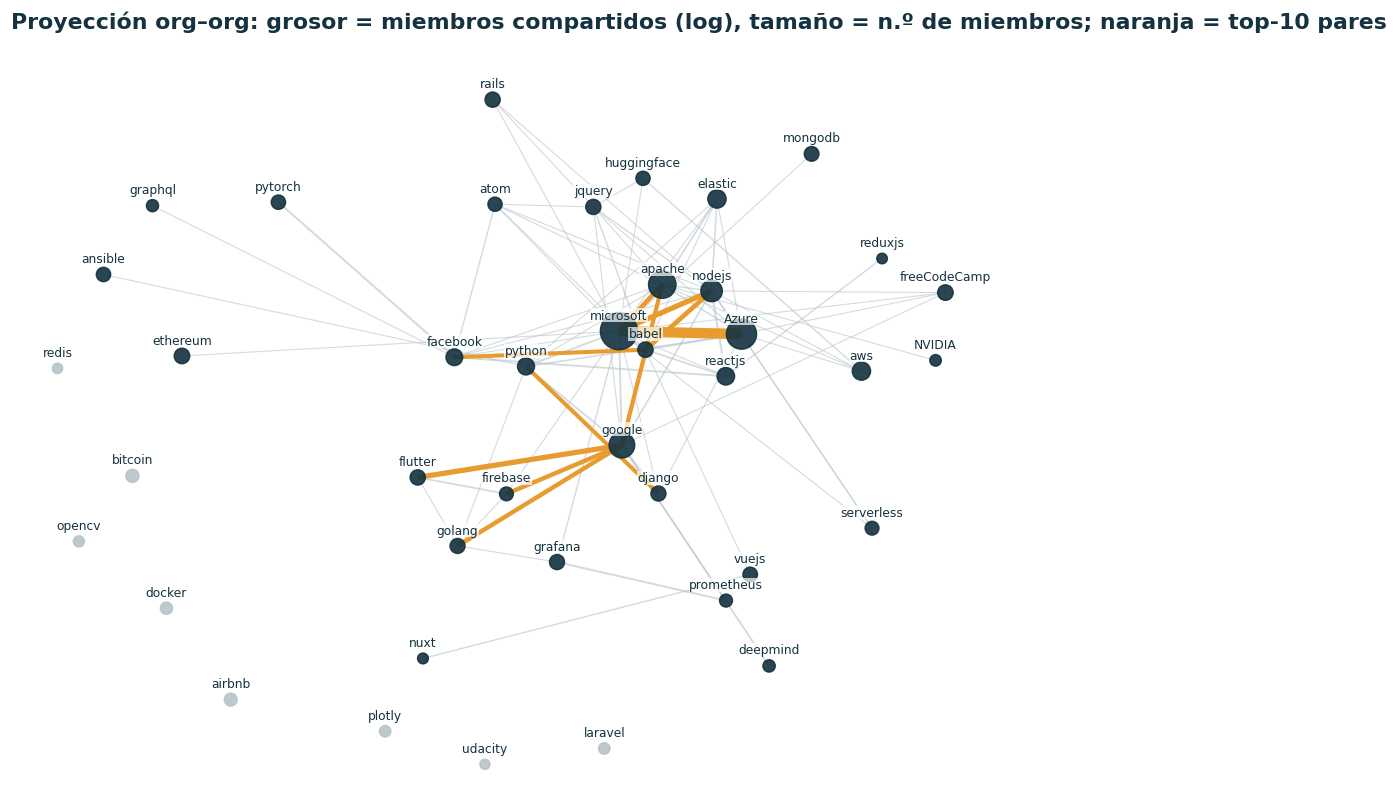

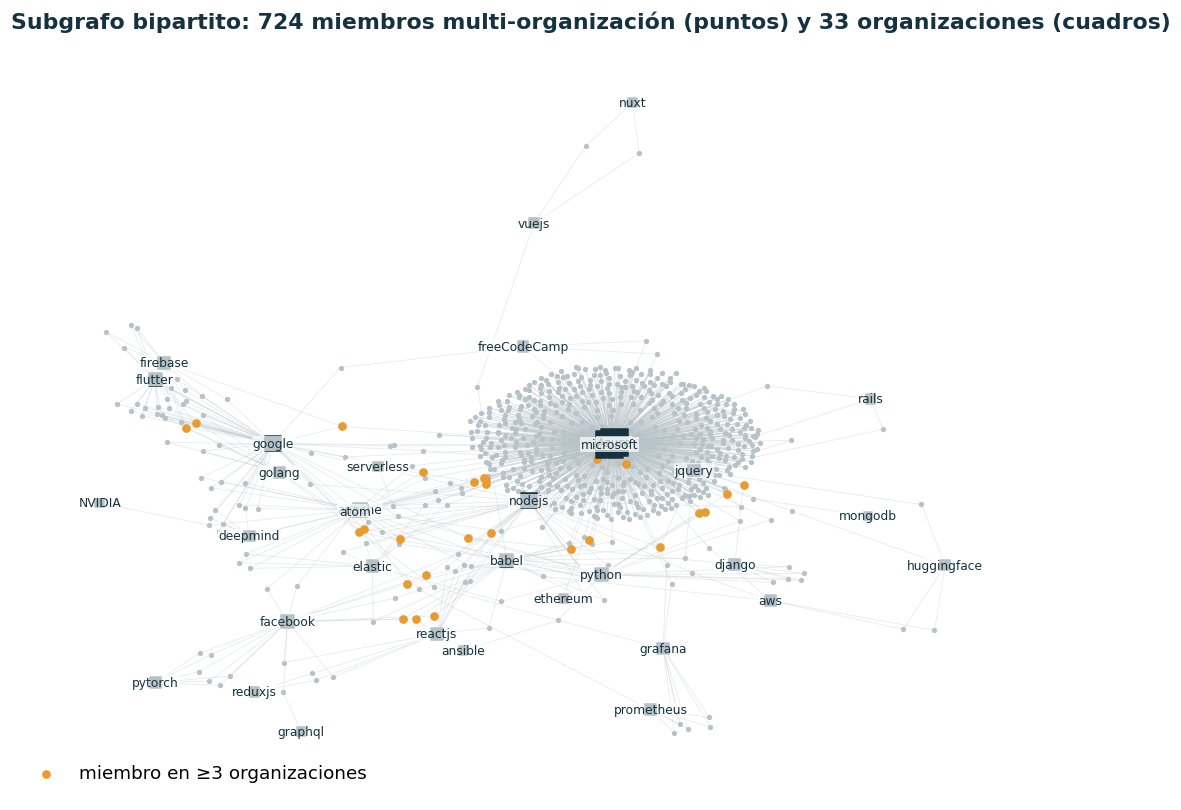

Organizaciones sin ningún miembro compartido: ['airbnb', 'bitcoin', 'docker', 'laravel', 'opencv', 'plotly', 'redis', 'udacity']


In [4]:
# ===== Fase 2: proyección ponderada sobre organizaciones y visualización =====
# ⚠️ NO proyectamos sobre miembros: generaría ~10 millones de aristas (cada org grande es un clique)
P = bipartite.weighted_projected_graph(B, orgs)                   # arista org-org, weight = miembros compartidos
for u, v, d in P.edges(data=True):
    d['distancia'] = 1 / d['weight']                              # más miembros compartidos = más "cerca"
    d['peso_log'] = np.log1p(d['weight'])                         # versión logarítmica (para fase 3)
nx.set_node_attributes(P, {o: B.degree(o) for o in orgs}, 'miembros')
print(P, '| densidad:', round(nx.density(P), 3))

tam = pd.Series({o: B.degree(o) for o in orgs})
pares = pd.DataFrame([(u, v, d['weight'], d['weight'] / min(tam[u], tam[v]),
                       d['weight'] / (tam[u] + tam[v] - d['weight'])) for u, v, d in P.edges(data=True)],
                     columns=['org_1', 'org_2', 'miembros_compartidos', 'solapamiento_min', 'jaccard'])
print('\nTop-10 pares por miembros compartidos:')
print(pares.sort_values('miembros_compartidos', ascending=False).head(10).round(3).to_string(index=False))
print('\nTop-5 pares por Jaccard (solapamiento relativo, corrige el tamaño):')
print(pares.sort_values('jaccard', ascending=False).head(5).round(3).to_string(index=False))

# --- Gráfico 1: proyección. Qué analizamos: qué organizaciones comparten desarrolladores y con qué intensidad ---
pos = nx.spring_layout(P, weight='peso_log', seed=SEMILLA, k=0.9)
top_aristas = set(map(tuple, pares.nlargest(10, 'miembros_compartidos')[['org_1', 'org_2']].values))
wmax = np.log1p(max(nx.get_edge_attributes(P, 'weight').values()))
fig, ax = plt.subplots(figsize=(12, 9))
otras = [(u, v) for u, v in P.edges() if (u, v) not in top_aristas and (v, u) not in top_aristas]
nx.draw_networkx_edges(P, pos, edgelist=otras, ax=ax, edge_color=GRIS, alpha=0.6,
                       width=[0.4 + 3 * P[u][v]['peso_log'] / wmax for u, v in otras])
nx.draw_networkx_edges(P, pos, edgelist=list(top_aristas), ax=ax, edge_color=ACENTO,
                       width=[0.8 + 6 * P[u][v]['peso_log'] / wmax for u, v in top_aristas])
nx.draw_networkx_nodes(P, pos, ax=ax, node_size=[25 + 9 * np.sqrt(tam[o]) for o in P],
                       node_color=[TINTA if P.degree(o) else GRIS for o in P], alpha=0.9)
nx.draw_networkx_labels(P, {o: (x, y + 0.045) for o, (x, y) in pos.items()}, ax=ax, font_size=8, font_color=TINTA,
                        bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=0.3))
ax.set_title('Proyección org–org: grosor = miembros compartidos (log), tamaño = n.º de miembros; naranja = top-10 pares')
ax.axis('off'); plt.show()

# --- Gráfico 2: subgrafo bipartito de los miembros multi-organización (los puentes reales) ---
orgs_multi = sorted({o for m in multi for o in B[m]})
S = B.subgraph(orgs_multi + multi)
pos_s = nx.spring_layout(S, seed=SEMILLA, k=0.08, iterations=80)
fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx_edges(S, pos_s, ax=ax, edge_color=GRIS, alpha=0.35, width=0.5)
nx.draw_networkx_nodes(S, pos_s, nodelist=[m for m in multi if B.degree(m) == 2], ax=ax, node_size=6, node_color=GRIS)
nx.draw_networkx_nodes(S, pos_s, nodelist=[m for m in multi if B.degree(m) >= 3], ax=ax, node_size=22, node_color=ACENTO,
                       label='miembro en ≥3 organizaciones')
nx.draw_networkx_nodes(S, pos_s, nodelist=orgs_multi, ax=ax, node_shape='s', node_color=TINTA,
                       node_size=[20 + 4 * np.sqrt(S.degree(o)) * 3 for o in orgs_multi])
nx.draw_networkx_labels(S, pos_s, labels={o: o for o in orgs_multi}, ax=ax, font_size=8, font_color=TINTA,
                        bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=0.5))
ax.set_title(f'Subgrafo bipartito: {len(multi)} miembros multi-organización (puntos) y {len(orgs_multi)} organizaciones (cuadros)')
ax.legend(loc='lower left'); ax.axis('off'); plt.show()
print('Organizaciones sin ningún miembro compartido:', sorted(set(orgs) - set(orgs_multi)))

**Conclusión de negocio:**
- La proyección tiene 41 organizaciones y 84 aristas (densidad 0,10). Un solo par domina todo: **Azure–microsoft comparten 555 miembros**. Le siguen, muy lejos, microsoft–nodejs (15), flutter–google (15), apache–microsoft (10), babel–nodejs (10), firebase–google (8) y golang–google (8).
- Si se corrige por tamaño (Jaccard), aparecen afinidades temáticas que el conteo bruto esconde: grafana–prometheus (observabilidad), facebook–pytorch, firebase–flutter (móvil) y nuxt–vuejs.
- La visualización muestra un núcleo microsoft/Azure/apache/nodejs y, alrededor, dos ecosistemas: uno de **Google** (flutter, firebase, golang, python–django) y otro de **JavaScript** (nodejs, babel, reactjs, facebook). Hay **8 organizaciones aisladas** que no comparten ningún miembro: airbnb, bitcoin, docker, laravel, opencv, plotly, redis y udacity.
- En el subgrafo bipartito se ve que casi todos los puentes son dobles membresías microsoft–Azure (el "abanico" central). Los 27 miembros en 3 organizaciones (naranja) cruzan sobre todo el eje JavaScript–Facebook.
- Para la fundación, la colaboración entre organizaciones es escasa y está concentrada. Fuera del bloque Microsoft, cada vínculo depende de unas pocas personas.

<a id="fase-3"></a>
## Fase 3: Centralidades

Paso 3. Grado, cercanía, intermediación, vector propio y **PageRank** en la proyección (usen el peso con criterio: en cercanía e intermediación el peso es *distancia*, así que hay que invertirlo). Comparen los rankings (correlación de Spearman) y expliquen qué organización es más central según cada medida y por qué difieren; ¿qué aporta PageRank frente al vector propio? **Pista:** la proyección no es conexa, así que el vector propio se calcula sobre la **componente gigante**. Si el vector propio ponderado no converge, revisen la distribución de pesos (una sola arista puede dominar), prueben `eigenvector_centrality_numpy` o pesos en escala logarítmica, y discutan qué versión responde mejor la pregunta de negocio.

> **Pregunta de la guía:** Top-3 por cada centralidad (incluido PageRank) y correlación de Spearman. ¿Por qué difieren los rankings?

**Qué analizamos:** qué organización es más importante según cinco criterios distintos (grado, cercanía, intermediación, vector propio y PageRank) y cuánto coinciden sus rankings.

Componente gigante: 33 de 41 organizaciones, 84 aristas
Pesos: mediana 1.0 | media 9.3 | máximo 555 ('Azure', 'microsoft') | la arista más pesada concentra el 71.3% del peso total
Vector propio ponderado: NO convergió -> eigenvector_centrality_numpy

Top-3 por centralidad:
                                 1.º             2.º             3.º
grado              microsoft (0.475)  nodejs (0.350)  google (0.325)
cercania           microsoft (1.243)   Azure (1.240)  nodejs (1.220)
intermediacion     microsoft (0.401)  nodejs (0.290)   babel (0.199)
vector_propio_log  microsoft (0.519)   Azure (0.429)  nodejs (0.355)
vector_propio_w    microsoft (0.707)   Azure (0.707)  nodejs (0.023)
pagerank           microsoft (0.227)   Azure (0.200)  google (0.065)

Correlación de Spearman (componente gigante):
                   grado  cercania  intermediacion  vector_propio_log  vector_propio_w  pagerank  miembros
grado               1.00      0.81            0.72               0.95             0.87   

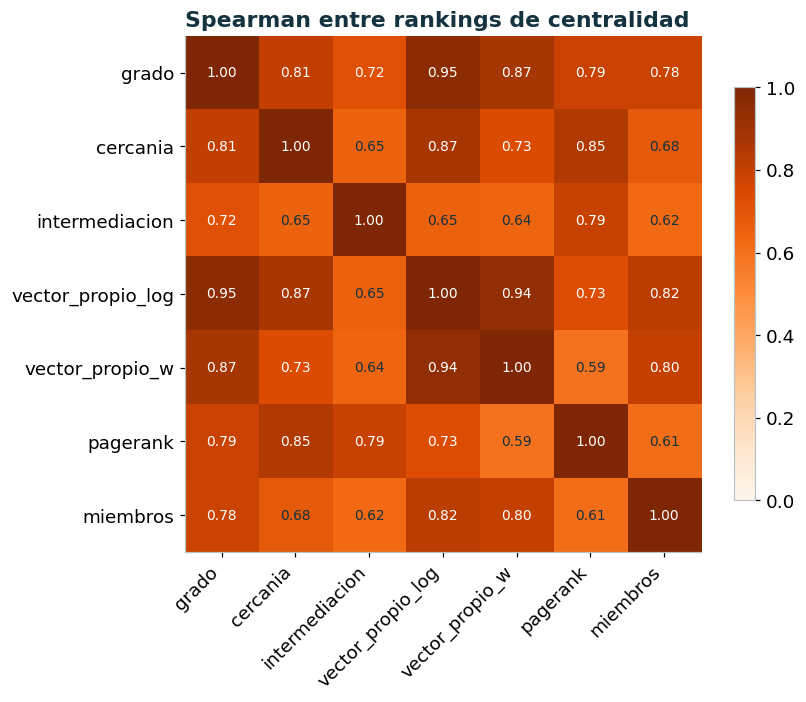

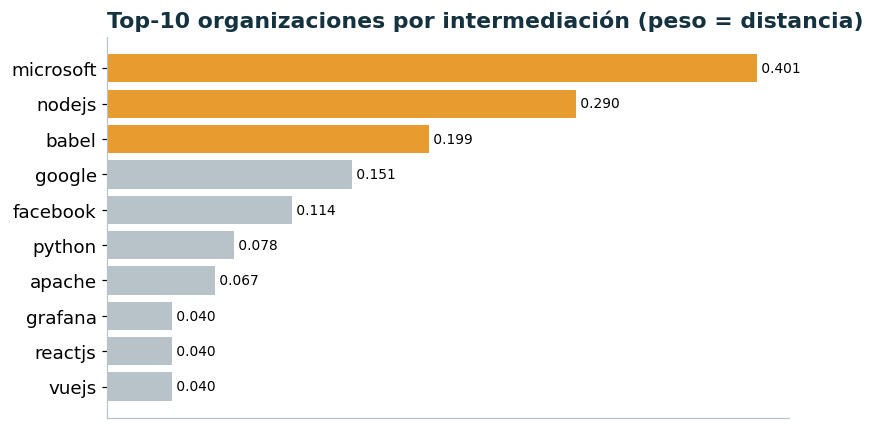

In [5]:
# ===== Fase 3: centralidades en la proyección =====
G = P.subgraph(max(nx.connected_components(P), key=len)).copy()   # componente gigante (la proyección no es conexa)
print(f'Componente gigante: {G.number_of_nodes()} de {P.number_of_nodes()} organizaciones, {G.number_of_edges()} aristas')

# Distribución de pesos: ¿una arista domina?
w = pd.Series(nx.get_edge_attributes(G, 'weight'))
print('Pesos: mediana', w.median(), '| media', round(w.mean(), 1), '| máximo', w.max(), w.idxmax(),
      f'| la arista más pesada concentra el {100 * w.max() / w.sum():.1f}% del peso total')

cent = pd.DataFrame(index=sorted(P))
cent['grado'] = pd.Series(nx.degree_centrality(P))                           # n.º de organizaciones socias (normalizado)
cent['cercania'] = pd.Series(nx.closeness_centrality(P, distance='distancia'))  # peso como DISTANCIA (1/weight)
cent['intermediacion'] = pd.Series(nx.betweenness_centrality(P, weight='distancia'))  # peso como DISTANCIA
cent['pagerank'] = pd.Series(nx.pagerank(P, weight='weight'))                 # peso como fuerza del enlace

# Vector propio (solo componente gigante). Ponderado por iteración de potencias, con respaldo numpy y log
try:
    ev_w = nx.eigenvector_centrality(G, weight='weight', max_iter=1000)
    estado = 'convergió (iteración de potencias)'
except nx.PowerIterationFailedConvergence:
    ev_w = nx.eigenvector_centrality_numpy(G, weight='weight')
    estado = 'NO convergió -> eigenvector_centrality_numpy'
print('Vector propio ponderado:', estado)
cent['vector_propio_w'] = pd.Series(ev_w)
cent['vector_propio_log'] = pd.Series(nx.eigenvector_centrality_numpy(G, weight='peso_log'))
cent['vector_propio'] = pd.Series(nx.eigenvector_centrality_numpy(G))         # sin peso (estructura pura)
cent['miembros'] = tam

medidas = ['grado', 'cercania', 'intermediacion', 'vector_propio_log', 'vector_propio_w', 'pagerank']
top3 = pd.DataFrame({m: [f'{o} ({v:.3f})' for o, v in cent[m].nlargest(3).items()] for m in medidas},
                    index=['1.º', '2.º', '3.º']).T
print('\nTop-3 por centralidad:'); print(top3.to_string())

rho = cent.loc[list(G), medidas + ['miembros']].corr(method='spearman')       # correlación de rangos en la componente gigante
print('\nCorrelación de Spearman (componente gigante):'); print(rho.round(2).to_string())

# --- Gráfico: qué analizamos: cuánto coinciden los rankings de cada medida ---
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(rho.values, cmap='Oranges', vmin=0, vmax=1)
ax.set_xticks(range(len(rho)), rho.columns, rotation=45, ha='right'); ax.set_yticks(range(len(rho)), rho.index)
for i in range(len(rho)):
    for j in range(len(rho)):
        ax.text(j, i, f'{rho.values[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if rho.values[i, j] > 0.7 else TINTA)
ax.set_title('Spearman entre rankings de centralidad'); plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

# --- Gráfico: top-10 por intermediación (los puentes) ---
top_bc = cent['intermediacion'].nlargest(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top_bc.index, top_bc.values, color=[ACENTO if i >= 7 else GRIS for i in range(10)])
for y, v in enumerate(top_bc.values): ax.text(v, y, f' {v:.3f}', va='center', fontsize=9)
ax.set_title('Top-10 organizaciones por intermediación (peso = distancia)'); ax.set_xticks([]); plt.show()

**Conclusión de negocio:**
- **Top-3** (componente gigante de 33 organizaciones):
  - grado: microsoft, nodejs, google
  - cercanía: microsoft, Azure, nodejs
  - intermediación: microsoft (0,40), nodejs (0,29), babel (0,20)
  - vector propio (log): microsoft, Azure, nodejs
  - PageRank: microsoft (0,23), Azure (0,20), google (0,07)
- **microsoft es la organización más central con todas las medidas.** Las diferencias aparecen del 2.º lugar en adelante.
- **Spearman:** grado y vector propio (log) casi coinciden (0,95). La intermediación es la medida que menos se parece a las demás (0,64–0,79): mide *puente*, no tamaño. Por eso babel (solo 69 miembros) entra al top-3, porque conecta el mundo JavaScript con facebook, vuejs y nuxt.
- **Vector propio ponderado:** con iteración de potencias no converge, porque la arista microsoft–Azure concentra el 71 % del peso total. La versión `numpy` devuelve 0,707 para ambas y casi 0 para el resto, así que no discrimina. Con pesos log (`log1p`), el ranking es útil (microsoft 0,52, Azure 0,43, nodejs 0,36) y es la versión que responde mejor la pregunta de negocio.
- **PageRank vs. vector propio:** PageRank reparte la importancia de cada nodo entre sus vecinos y añade teletransporte. Así queda definido en la red no conexa y una sola arista lo domina menos (correlación con el vector propio ponderado de solo 0,59). Por eso google, que es puente de su propio ecosistema, sube al 3.er lugar.
- *Nota:* la cercanía ponderada es mayor que 1 porque la distancia es 1/peso (< 1).

<a id="fase-4"></a>
## Fase 4: Componentes conectados y propiedades de la red

Paso 3. Componentes conectados (¿qué organizaciones quedan aisladas?), distribución de grado del bipartito, coeficiente de clustering, diámetro y longitud media de caminos de la componente gigante. Interpreten qué dicen sobre el ecosistema.

> **Pregunta de la guía:** Componentes, organizaciones aisladas, clustering, diámetro y longitud media. ¿Qué dicen del ecosistema?

**Qué analizamos:** si el ecosistema está unido o fragmentado (componentes), cómo se reparten los miembros entre organizaciones (distribución de grado) y si es una red de "mundo pequeño" (clustering, diámetro y longitud media de caminos).

Proyección: componentes = 9 | tamaños: [33, 1, 1, 1, 1, 1, 1, 1, 1]
Organizaciones aisladas (no comparten ningún miembro): ['airbnb', 'bitcoin', 'docker', 'laravel', 'opencv', 'plotly', 'redis', 'udacity']
Componentes pequeñas (2+ nodos fuera de la gigante): []

Bipartito: componentes = 9 | gigante = 8,800 nodos (98.7% del total)


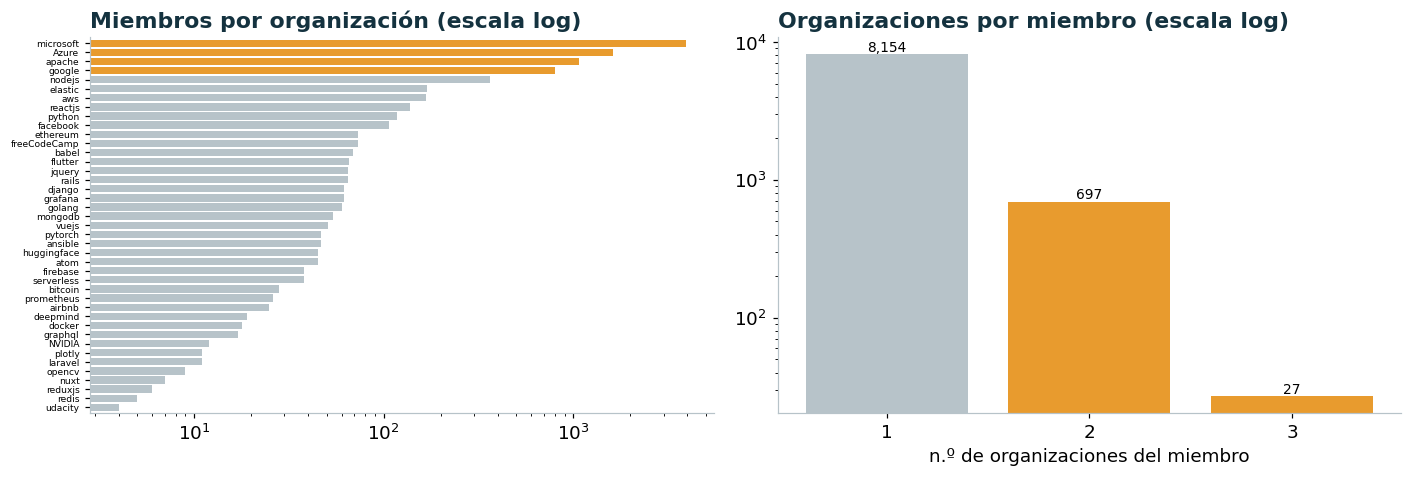

Grado de organizaciones: mediana 51.0 | máx 3916 | las 4 mayores suman 76.9% de las membresías
clustering medio P (sin peso)                            0.349
clustering medio P (ponderado)                           0.002
transitividad P                                          0.376
clustering grafo aleatorio equivalente (30 semillas)     0.162
diámetro gigante P (saltos)                              5.000
longitud media gigante P (saltos)                        2.301
longitud media gigante P (ponderada, 1/peso)             1.176
diámetro gigante B (aprox., saltos)                     12.000
longitud media gigante B (muestra 300 orígenes)          3.902


In [6]:
# ===== Fase 4: componentes conectados y propiedades de la red =====
comp_P = sorted(nx.connected_components(P), key=len, reverse=True)
print('Proyección: componentes =', len(comp_P), '| tamaños:', [len(c) for c in comp_P])
aisladas = sorted(nx.isolates(P))
print('Organizaciones aisladas (no comparten ningún miembro):', aisladas)
print('Componentes pequeñas (2+ nodos fuera de la gigante):', [sorted(c) for c in comp_P[1:] if len(c) > 1])

comp_B = sorted(nx.connected_components(B), key=len, reverse=True)
print(f'\nBipartito: componentes = {len(comp_B)} | gigante = {len(comp_B[0]):,} nodos '
      f'({100 * len(comp_B[0]) / B.number_of_nodes():.1f}% del total)')

# --- Distribución de grado del bipartito. Qué analizamos: ¿hay pocas organizaciones enormes y muchos miembros de 1 org? ---
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
tam.sort_values().plot.barh(ax=axs[0], color=[ACENTO if v > 800 else GRIS for v in tam.sort_values()], width=0.8)
axs[0].set_xscale('log'); axs[0].set_title('Miembros por organización (escala log)'); axs[0].tick_params(axis='y', labelsize=6)
vc = orgs_por_miembro.value_counts().sort_index()
axs[1].bar(vc.index.astype(str), vc.values, color=[GRIS] + [ACENTO] * (len(vc) - 1)); axs[1].set_yscale('log')
for x, v in zip(vc.index.astype(str), vc.values): axs[1].text(x, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
axs[1].set_title('Organizaciones por miembro (escala log)'); axs[1].set_xlabel('n.º de organizaciones del miembro')
plt.tight_layout(); plt.show()
print('Grado de organizaciones: mediana', tam.median(), '| máx', tam.max(), '| las 4 mayores suman',
      f'{100 * tam.nlargest(4).sum() / tam.sum():.1f}% de las membresías')

# --- Clustering y caminos ---
props = {}
props['clustering medio P (sin peso)'] = nx.average_clustering(G)
props['clustering medio P (ponderado)'] = nx.average_clustering(G, weight='weight')
props['transitividad P'] = nx.transitivity(G)
alea = [nx.average_clustering(nx.gnm_random_graph(G.number_of_nodes(), G.number_of_edges(), seed=s)) for s in range(30)]
props['clustering grafo aleatorio equivalente (30 semillas)'] = np.mean(alea)
props['diámetro gigante P (saltos)'] = nx.diameter(G)
props['longitud media gigante P (saltos)'] = nx.average_shortest_path_length(G)
props['longitud media gigante P (ponderada, 1/peso)'] = nx.average_shortest_path_length(G, weight='distancia')
GB = B.subgraph(comp_B[0])
props['diámetro gigante B (aprox., saltos)'] = nx.approximation.diameter(GB, seed=SEMILLA)
rng = random.Random(SEMILLA); fuentes = rng.sample(list(GB), 300)       # muestra de 300 orígenes (B tiene ~9 mil nodos)
props['longitud media gigante B (muestra 300 orígenes)'] = np.mean([np.mean(list(nx.single_source_shortest_path_length(GB, s).values())[1:]) for s in fuentes])
print(pd.Series(props).round(3).to_string())

**Conclusión de negocio:**
- **Componentes:** la proyección tiene 9 componentes: una gigante con **33 organizaciones** y **8 aisladas** (airbnb, bitcoin, docker, laravel, opencv, plotly, redis y udacity). En el bipartito, la gigante reúne al 98,7 % de los nodos.
- **Grado muy desigual:** la mediana es de 51 miembros por organización, pero microsoft tiene 3 916, y las 4 mayores (microsoft, Azure, apache, google) suman el 77 % de las membresías. Del lado de los miembros, 8 154 están en una sola organización.
- **Clustering:** el coeficiente medio de la proyección es 0,35, unas 2 veces el de un grafo aleatorio equivalente (0,16), y la transitividad es 0,38. Hay grupos temáticos más cohesionados que al azar. El clustering ponderado (0,002) es bajo porque normaliza por el peso máximo (555).
- **Caminos:** en la gigante el diámetro es 5 saltos y la longitud media 2,3. En el bipartito el diámetro es de unos 12 saltos y la longitud media de unos 3,9 (muestra de 300 orígenes).
- **Qué dice del ecosistema:** es un **mundo pequeño centralizado** (*hub and spoke*). Cualquier par de organizaciones conectadas está a 2–3 pasos, casi siempre a través de microsoft. Eso facilita que circule el conocimiento, pero lo hace depender de pocos hubs. Las 8 organizaciones aisladas son comunidades cerradas, sin intercambio de talento visible con el resto.

<a id="fase-5"></a>
## Fase 5: Resiliencia y robustez

Paso 3. Simulen la eliminación progresiva de nodos: **aleatoria** frente a **dirigida** (por grado y por intermediación). Grafiquen el tamaño relativo de la componente gigante frente a la fracción eliminada. Identifiquen los **puntos de articulación** de la proyección (`nx.articulation_points`): ¿qué organizaciones desconectan la red por sí solas? ¿Qué nodos sostienen la red? Esta fase alimenta el desafío 1.

> **Pregunta de la guía:** ¿Con qué fracción eliminada se rompe la componente gigante en el ataque dirigido vs. el aleatorio? ¿Cuáles son los puntos de articulación?

**Qué analizamos:** cuánto resiste la red de organizaciones cuando salen nodos al azar frente a cuando se ataca a los más centrales, qué organizaciones la desconectan por sí solas (puntos de articulación) y qué desarrolladores sostienen solos una conexión.

                             fracción para gigante < 50 %  n.º de orgs eliminadas  gigante tras quitar 10 %
aleatorio (media de 200)                            0.415                    17.0                     0.875
dirigido por grado                                  0.146                     6.0                     0.727
dirigido por intermediación                         0.122                     5.0                     0.727


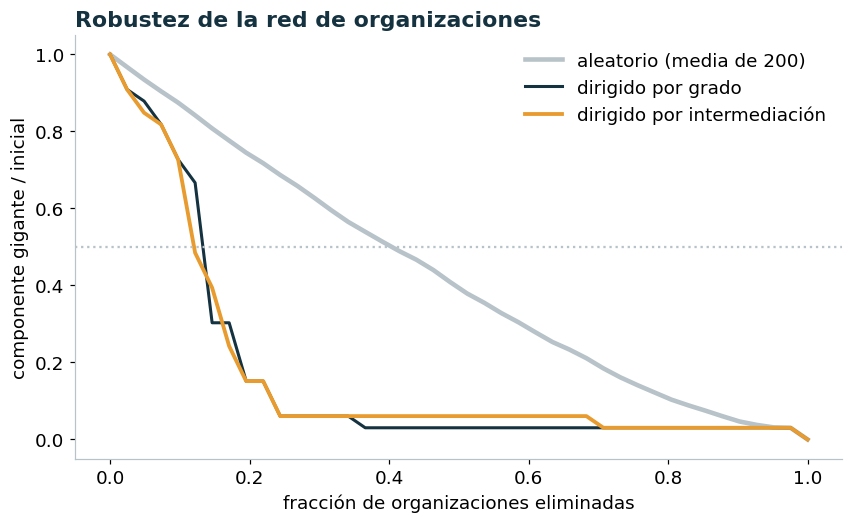


Puntos de articulación: ['apache', 'babel', 'facebook', 'google', 'microsoft', 'python', 'reactjs', 'vuejs']
           articulación  gigante tras quitarla  componentes  orgs desconectadas
org                                                                            
facebook           True                     30            3                   2
microsoft          True                     30            3                   2
babel              True                     30            2                   2
apache             True                     31            2                   1
google             True                     31            2                   1
python             True                     31            2                   1
reactjs            True                     31            2                   1
vuejs              True                     31            2                   1
  sin apache: quedan sueltas [['NVIDIA']]
  sin babel: quedan sueltas [['nuxt', 'vuejs']]


In [7]:
# ===== Fase 5: resiliencia y robustez de la proyección =====
S0 = len(max(nx.connected_components(P), key=len))                # tamaño inicial de la componente gigante
n0 = P.number_of_nodes()

def gigante_rel(H):                                               # tamaño de la componente gigante / tamaño inicial
    return max((len(c) for c in nx.connected_components(H)), default=0) / S0

def simular(estrategia, rng=None):
    H = P.copy(); curva = [gigante_rel(H)]
    for _ in range(n0):
        if estrategia == 'aleatorio':
            v = rng.choice(sorted(H))
        elif estrategia == 'grado':                               # ataque dirigido adaptativo: se recalcula en cada paso
            v = max(H.degree(), key=lambda t: (t[1], t[0]))[0]
        else:                                                     # intermediación recalculada (peso = distancia)
            bc = nx.betweenness_centrality(H, weight='distancia'); v = max(bc, key=lambda k: (bc[k], k))
        H.remove_node(v); curva.append(gigante_rel(H))
    return np.array(curva)

fr = np.arange(n0 + 1) / n0
curvas = {'aleatorio (media de 200)': np.mean([simular('aleatorio', random.Random(s)) for s in range(200)], axis=0),
          'dirigido por grado': simular('grado'), 'dirigido por intermediación': simular('intermediacion')}

def umbral(c, nivel=0.5):                                         # primera fracción con gigante < 50 % del inicial
    return fr[np.argmax(c < nivel)]
tabla_rob = pd.DataFrame({k: {'fracción para gigante < 50 %': round(umbral(c), 3),
                              'n.º de orgs eliminadas': int(round(umbral(c) * n0)),
                              'gigante tras quitar 10 %': round(c[int(round(0.1 * n0))], 3)} for k, c in curvas.items()}).T
print(tabla_rob.to_string())

# --- Gráfico. Qué analizamos: cuánto aguanta la red ante fallos al azar vs. ataques a los nodos clave ---
fig, ax = plt.subplots(figsize=(9, 5))
estilos = {'aleatorio (media de 200)': dict(color=GRIS, lw=3), 'dirigido por grado': dict(color=TINTA, lw=2),
           'dirigido por intermediación': dict(color=ACENTO, lw=2.5)}
for k, c in curvas.items(): ax.plot(fr, c, label=k, **estilos[k])
ax.axhline(0.5, ls=':', color=GRIS); ax.set_xlabel('fracción de organizaciones eliminadas')
ax.set_ylabel('componente gigante / inicial'); ax.set_title('Robustez de la red de organizaciones'); ax.legend(); plt.show()

# --- Puntos de articulación: organizaciones que, solas, desconectan la red ---
art = sorted(nx.articulation_points(P))
print('\nPuntos de articulación:', art)
imp = []
for o in sorted(G):                                               # impacto de quitar UNA organización
    H = G.copy(); H.remove_node(o); cs = sorted(map(len, nx.connected_components(H)), reverse=True)
    imp.append({'org': o, 'articulación': o in art, 'gigante tras quitarla': cs[0], 'componentes': len(cs),
                'orgs desconectadas': G.number_of_nodes() - 1 - cs[0]})
impacto = pd.DataFrame(imp).set_index('org').sort_values(['orgs desconectadas', 'componentes'], ascending=False)
print(impacto.head(8).to_string())
for o in art:
    H = G.copy(); H.remove_node(o)
    print(f'  sin {o}: quedan sueltas', [sorted(c) for c in nx.connected_components(H) if len(c) < G.number_of_nodes() - 1 - 1 and len(c) < 10])

# --- Desarrolladores puente: miembros cuya salida corta aristas org-org (aristas de peso 1 que dependen de una sola persona) ---
unico = {}                                                        # arista org-org -> único miembro que la sostiene
for u, v, d in G.edges(data=True):
    if d['weight'] == 1:
        unico[(u, v)] = next(iter(set(B[u]) & set(B[v])))
dev = pd.Series(unico).reset_index().rename(columns={0: 'miembro'}).groupby('miembro').size().rename('aristas_que_sostiene_solo')
filas = []
for m in dev.index:
    H = G.copy(); H.remove_edges_from([e for e, mm in unico.items() if mm == m])
    cs = sorted(map(len, nx.connected_components(H)), reverse=True)
    filas.append({'miembro': m, 'orgs del miembro': B.degree(m), 'aristas que sostiene solo': dev[m],
                  'orgs que se desconectan': G.number_of_nodes() - cs[0]})
puentes_dev = pd.DataFrame(filas)
# Ética: seudonimizamos a las personas (dev_<índice>); el nombre real no aporta al análisis estructural
puentes_dev['miembro'] = [f'dev_{multi.index(m):03d}' for m in puentes_dev['miembro']]
puentes_dev = puentes_dev.sort_values(['orgs que se desconectan', 'aristas que sostiene solo'], ascending=False)
print(f'\n{len(unico)} de {G.number_of_edges()} aristas org-org dependen de UN solo desarrollador '
      f'({100 * len(unico) / G.number_of_edges():.0f}%).')
print('Desarrolladores cuya salida desconecta organizaciones:', (puentes_dev['orgs que se desconectan'] > 0).sum())
print(puentes_dev.head(8).to_string(index=False))

**Conclusión de negocio:**
- **Ataque dirigido vs. aleatorio:** la componente gigante cae bajo el 50 % de su tamaño inicial al quitar el **12 % de las organizaciones (5) con un ataque por intermediación** y el **15 % (6) con un ataque por grado**. Con fallos aleatorios hace falta quitar el **41 % (17)** (media de 200 simulaciones). Tras quitar el 10 %, la gigante conserva el 88 % con fallos al azar, pero solo el 73 % con ataques. La red es robusta ante fallos y frágil ante ataques: es lo típico de una red con hubs.
- **Puntos de articulación (8):** apache, babel, facebook, google, microsoft, python, reactjs y vuejs. Lo que se desconecta al quitar cada uno:
  - microsoft: ethereum y mongodb
  - facebook: pytorch y graphql
  - babel: vuejs y nuxt
  - google: deepmind
  - apache: NVIDIA
  - python: ansible
  - reactjs: reduxjs
  - vuejs: nuxt
- **Desarrolladores puente:** el **57 % de las conexiones org–org (48 de 84) dependen de una sola persona**, y la salida de 6 desarrolladores, cada uno por separado, desconecta al menos una organización.
- Los nodos que sostienen la red son microsoft (núcleo), google, python y babel/facebook (puentes entre ecosistemas). La fundación debería proteger estos vínculos: mantenedores compartidos y proyectos comunes. Su salida fragmenta la red mucho más que la de las organizaciones grandes, pero periféricas.

<a id="fase-6"></a>
## Fase 6: Caminos: BFS, DFS, Dijkstra y Floyd-Warshall

Paso 4. Recorran la red con BFS y DFS desde una organización y comparen el orden de visita. Calculen el camino mínimo ponderado entre dos organizaciones con **Dijkstra** y todos los caminos mínimos con **Floyd-Warshall** sobre la proyección de organizaciones (distancia = 1/peso). Expliquen por qué Floyd-Warshall no conviene en el grafo completo (complejidad O(n³)) y cuándo Dijkstra es la alternativa.

> **Pregunta de la guía:** Orden de visita BFS vs. DFS, camino de Dijkstra entre dos organizaciones y por qué Floyd-Warshall no escala (O(n³)).

**Qué analizamos:** cómo se recorre la red desde microsoft (BFS por niveles vs. DFS en profundidad), cuál es el camino más "fuerte" entre dos organizaciones (Dijkstra con distancia = 1/miembros compartidos) y por qué Floyd-Warshall no escala.

Niveles BFS desde microsoft: {0: 1, 1: 19, 2: 12, 3: 1}
             BFS  nivel BFS          DFS  profundidad DFS
0      microsoft          0    microsoft                0
1          Azure          1        Azure                1
2         apache          1       apache                2
3           atom          1       NVIDIA                3
4          babel          1         atom                3
5         django          1        babel                4
6        elastic          1      elastic                5
7       ethereum          1       nodejs                6
8       facebook          1          aws                7
9       firebase          1  huggingface                8
10  freeCodeCamp          1       jquery                9
11        google          1       google               10
12       grafana          1     deepmind               11
13   huggingface          1       django               11
14       mongodb          1       python               12

django -> pytor

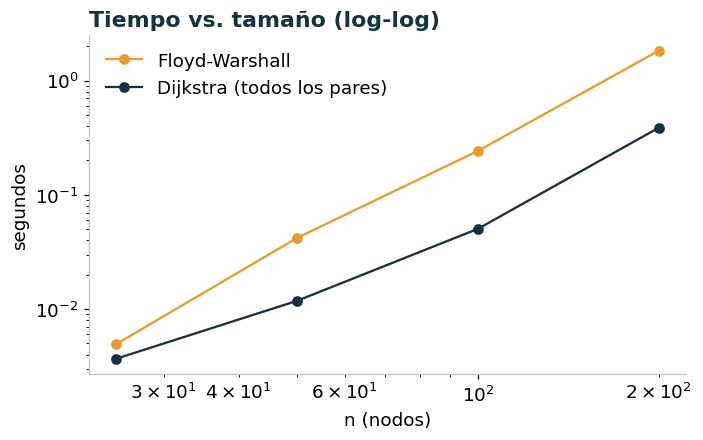

In [8]:
# ===== Fase 6: recorridos y caminos mínimos =====
origen = 'microsoft'
orden_bfs = [origen] + [v for _, v in nx.bfs_edges(G, origen, sort_neighbors=sorted)]
orden_dfs = list(nx.dfs_preorder_nodes(G, origen, sort_neighbors=sorted))
nivel = nx.single_source_shortest_path_length(G, origen)
T_dfs = nx.dfs_tree(G, origen, sort_neighbors=sorted)               # árbol DFS (para medir la profundidad de cada visita)
print('Niveles BFS desde microsoft:', pd.Series(nivel).value_counts().sort_index().to_dict())
recorrido = pd.DataFrame({'BFS': orden_bfs, 'nivel BFS': [nivel[o] for o in orden_bfs],
                          'DFS': orden_dfs, 'profundidad DFS': [nx.shortest_path_length(T_dfs, origen, o) for o in orden_dfs]})
print(recorrido.head(15).to_string())

# --- Dijkstra: camino ponderado (distancia = 1/miembros compartidos) vs. camino con menos saltos ---
for a, b in [('django', 'pytorch'), ('atom', 'firebase')]:
    if a in G and b in G:
        c_w = nx.dijkstra_path(G, a, b, weight='distancia'); d_w = nx.dijkstra_path_length(G, a, b, weight='distancia')
        c_h = nx.shortest_path(G, a, b)
        print(f'\n{a} -> {b}')
        print('  Dijkstra (1/peso):', ' -> '.join(c_w), f'| distancia = {d_w:.3f} | saltos = {len(c_w) - 1}')
        print('    pesos del camino:', [G[x][y]['weight'] for x, y in zip(c_w, c_w[1:])])
        print('  Menos saltos (BFS):', ' -> '.join(c_h), '| pesos:', [G[x][y]['weight'] for x, y in zip(c_h, c_h[1:])])

# --- Floyd-Warshall (todos los pares) vs. Dijkstra desde cada nodo ---
nodos = sorted(G)
t0 = time.perf_counter(); FW = nx.floyd_warshall_numpy(G, nodelist=nodos, weight='distancia'); t_fw_np = time.perf_counter() - t0
t0 = time.perf_counter(); fw_py = nx.floyd_warshall(G, weight='distancia'); t_fw = time.perf_counter() - t0
t0 = time.perf_counter(); DJ = dict(nx.all_pairs_dijkstra_path_length(G, weight='distancia')); t_dj = time.perf_counter() - t0
dif = max(abs(FW[i, j] - DJ[u][v]) for i, u in enumerate(nodos) for j, v in enumerate(nodos))
print(f'\nFloyd-Warshall ({len(nodos)} nodos): numpy {t_fw_np*1000:.1f} ms | python {t_fw*1000:.1f} ms | '
      f'Dijkstra todos los pares {t_dj*1000:.1f} ms | diferencia máx. = {dif:.2e}')
i, j = np.unravel_index(np.argmax(FW), FW.shape)
print('Par más lejano (ponderado):', nodos[i], '-', nodos[j], f'{FW[i, j]:.3f}')

# --- Escalamiento de Floyd-Warshall: O(n^3). Qué analizamos: cómo crece el tiempo con n ---
tiempos = []
for n in [25, 50, 100, 200]:
    R = nx.gnm_random_graph(n, 4 * n, seed=SEMILLA)
    t0 = time.perf_counter(); nx.floyd_warshall(R); t = time.perf_counter() - t0
    t0 = time.perf_counter(); dict(nx.all_pairs_dijkstra_path_length(R)); td = time.perf_counter() - t0
    tiempos.append({'n': n, 'Floyd-Warshall (s)': t, 'Dijkstra todos los pares (s)': td})
tiempos = pd.DataFrame(tiempos).set_index('n')
print(tiempos.round(4).to_string())
nB = B.number_of_nodes()
est = tiempos.iloc[-1, 0] * (nB / 200) ** 3
print(f'Extrapolación al bipartito completo ({nB:,} nodos): Floyd-Warshall ≈ {est/3600:,.1f} horas y matriz de '
      f'{nB**2 * 8 / 1e9:.2f} GB; Dijkstra desde UN origen en B es O((V+E) log V): milisegundos.')
t0 = time.perf_counter(); _ = nx.single_source_dijkstra_path_length(B, 'microsoft'); print(f'Dijkstra desde microsoft en B: {1000*(time.perf_counter()-t0):.1f} ms')
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(tiempos.index, tiempos.iloc[:, 0], 'o-', color=ACENTO, label='Floyd-Warshall')
ax.loglog(tiempos.index, tiempos.iloc[:, 1], 'o-', color=TINTA, label='Dijkstra (todos los pares)')
ax.set_xlabel('n (nodos)'); ax.set_ylabel('segundos'); ax.set_title('Tiempo vs. tamaño (log-log)'); ax.legend(); plt.show()

**Conclusión de negocio:**
- **BFS vs. DFS** desde microsoft: BFS visita por niveles. Primero los **19 socios directos** (nivel 1: Azure, apache, atom, babel…), luego 12 organizaciones en el nivel 2 y una en el 3. DFS se va en profundidad por una sola rama (microsoft → Azure → apache → NVIDIA → atom → babel…) y llega a profundidad 12 en la visita 15. BFS sirve para "quién está a k pasos" y DFS para explorar cadenas o detectar ciclos.
- **Dijkstra** (distancia = 1/miembros compartidos):
  - De django a pytorch, el camino más fuerte es django → python → microsoft → nodejs → babel → facebook → pytorch (distancia 0,87, 6 saltos, pesos 6-5-15-10-6-6). El camino más corto en saltos, django → microsoft → facebook → pytorch, pasa por aristas de 1 solo miembro (distancia 2,17).
  - Igual con atom → firebase: Dijkstra prefiere 6 saltos con muchos miembros compartidos a 2 saltos sostenidos por una persona.
  - Para transferir conocimiento importa la *fuerza* del vínculo, no solo el número de pasos.
- **Floyd-Warshall** sobre las 33 organizaciones toma milisegundos y da exactamente lo mismo que Dijkstra desde cada origen (diferencia ~1e-16). Su costo es **O(n³)** en tiempo y O(n²) en memoria: al duplicar n el tiempo crece unas 8 veces (de 0,074 s a 0,575 s al pasar de n = 100 a 200). En el bipartito completo (8 919 nodos) serían unas 14 horas y una matriz de 0,64 GB. Dijkstra con heap es O((V+E) log V) por origen (unos 12 ms desde microsoft en B). Conviene cuando el grafo es disperso o cuando solo se necesitan caminos desde algunos orígenes, que es el caso habitual.

<a id="fase-7"></a>
## Fase 7: Detección de comunidades

Paso 5. Apliquen y **comparen** Girvan-Newman, Louvain, **Leiden** (`nx.community.leiden_communities`, NetworkX ≥ 3.7, con `metric="modularity"` para compararlo con Louvain) y propagación de etiquetas. Verifiquen si alguna comunidad resulta internamente desconectada. Comparen modularidad, número y tamaño de comunidades, estabilidad entre semillas y tiempo. Argumenten cuál usarían y por qué.

> **Pregunta de la guía:** Modularidad, n.º de comunidades, estabilidad y tiempo por algoritmo. ¿Cuál eligen y por qué?

**Qué analizamos:** qué ecosistemas (comunidades) forman las organizaciones y qué algoritmo los detecta mejor según modularidad, número y tamaño de comunidades, estabilidad entre semillas, conexidad interna y tiempo.

                                 modularidad (mejor)  modularidad (media)  n.º comunidades                             tamaños  estabilidad ARI entre semillas  comunidades desconectadas  tiempo medio (ms)
algoritmo                                                                                                                                                                                                   
Girvan-Newman                                  0.081                0.081               11  [11, 5, 3, 3, 2, 2, 2, 2, 1, 1, 1]                           1.000                          0            321.722
Louvain                                        0.289                0.288                3                         [18, 11, 4]                           0.859                          0              2.962
Leiden                                         0.289                0.288                3                         [18, 11, 4]                           0.784                      

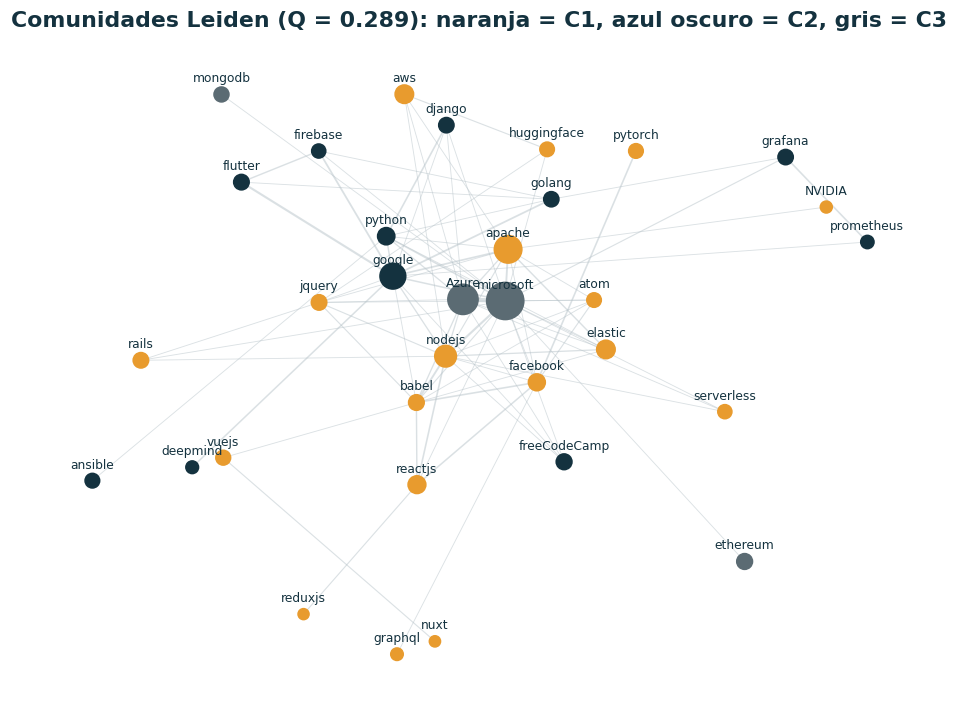

In [9]:
# ===== Fase 7: detección de comunidades (componente gigante de la proyección, peso = miembros compartidos) =====
from networkx.algorithms import community as nxc
from sklearn.metrics import adjusted_rand_score

def etiquetas(part):                                             # partición -> vector de etiquetas (para comparar)
    m = {n: i for i, c in enumerate(part) for n in c}; return [m[n] for n in sorted(G)]

def mejor_girvan_newman(Gx):
    # divisivo: quita la arista de mayor intermediación (peso = distancia) y se queda con el nivel de máxima modularidad
    def arista_mas_valiosa(H):
        eb = nx.edge_betweenness_centrality(H, weight='distancia'); return max(eb, key=eb.get)
    niveles = nxc.girvan_newman(Gx, most_valuable_edge=arista_mas_valiosa)
    return max((tuple(map(set, p)) for p in niveles), key=lambda p: nxc.modularity(Gx, p, weight='weight'))

algoritmos = {
    'Girvan-Newman': lambda s: mejor_girvan_newman(G),                                   # determinista
    'Louvain':       lambda s: nxc.louvain_communities(G, weight='weight', seed=s),
    'Leiden':        lambda s: nxc.leiden_communities(G, weight='weight', metric='modularity', seed=s),
    'Prop. etiquetas (asíncrona)': lambda s: nxc.asyn_lpa_communities(G, weight='weight', seed=s),
    'Prop. etiquetas (semi-síncrona)': lambda s: nxc.label_propagation_communities(G),  # determinista, sin peso
}
semillas = range(10)
filas, particiones = [], {}
for nombre, f in algoritmos.items():
    parts, ts = [], []
    for s in (semillas if nombre not in ('Girvan-Newman', 'Prop. etiquetas (semi-síncrona)') else [0]):
        t0 = time.perf_counter(); p = [set(c) for c in f(s)]; ts.append(time.perf_counter() - t0); parts.append(p)
    Q = [nxc.modularity(G, p, weight='weight') for p in parts]
    ari = [adjusted_rand_score(etiquetas(a), etiquetas(b)) for i, a in enumerate(parts) for b in parts[i + 1:]]
    mejor = parts[int(np.argmax(Q))]; particiones[nombre] = mejor
    filas.append({'algoritmo': nombre, 'modularidad (mejor)': max(Q), 'modularidad (media)': np.mean(Q),
                  'n.º comunidades': len(mejor), 'tamaños': sorted(map(len, mejor), reverse=True),
                  'estabilidad ARI entre semillas': np.mean(ari) if ari else 1.0,
                  'comunidades desconectadas': sum(not nx.is_connected(G.subgraph(c)) for p in parts for c in p),
                  'tiempo medio (ms)': 1000 * np.mean(ts)})
tabla_com = pd.DataFrame(filas).set_index('algoritmo')
print(tabla_com.round(3).to_string())

# Acuerdo entre algoritmos (ARI de las mejores particiones)
nombres = list(particiones)
acuerdo = pd.DataFrame([[adjusted_rand_score(etiquetas(particiones[a]), etiquetas(particiones[b])) for b in nombres] for a in nombres],
                       index=nombres, columns=nombres)
print('\nAcuerdo entre algoritmos (ARI):'); print(acuerdo.round(2).to_string())

# Sensibilidad: la arista microsoft-Azure concentra el 71 % del peso; probamos Leiden con peso logarítmico
p_log = nxc.leiden_communities(G, weight='peso_log', metric='modularity', seed=SEMILLA)
print('\nLeiden con peso log: Q(log) =', round(nxc.modularity(G, p_log, weight='peso_log'), 3), '| tamaños:', sorted(map(len, p_log), reverse=True))
for c in sorted(p_log, key=len, reverse=True): print('   ', sorted(c, key=lambda o: -tam[o]))

comunidades = sorted(particiones['Leiden'], key=len, reverse=True)   # partición elegida (se usa también en la fase 9)
print('\nComunidades Leiden (de mayor a menor):')
for i, c in enumerate(comunidades):
    print(f'  C{i+1} ({len(c)}):', sorted(c, key=lambda o: -tam[o]))

# --- Gráfico. Qué analizamos: qué ecosistemas forman las organizaciones según Leiden ---
paleta = [ACENTO, TINTA, '#5B6B73', '#7FA7B5', '#C9733A', GRIS, '#2E6F7E', '#D9C27A']
color = {o: paleta[i % len(paleta)] for i, c in enumerate(comunidades) for o in c}
pos_g = nx.spring_layout(G, weight='peso_log', seed=SEMILLA, k=0.9)
fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G, pos_g, ax=ax, edge_color=GRIS, alpha=0.5, width=[0.3 + 2.5 * G[u][v]['peso_log'] / wmax for u, v in G.edges()])
nx.draw_networkx_nodes(G, pos_g, ax=ax, node_color=[color[o] for o in G], node_size=[30 + 9 * np.sqrt(tam[o]) for o in G])
nx.draw_networkx_labels(G, {o: (x, y + 0.05) for o, (x, y) in pos_g.items()}, ax=ax, font_size=8, font_color=TINTA)
ax.set_title(f'Comunidades Leiden (Q = {nxc.modularity(G, comunidades, weight="weight"):.3f}): naranja = C1, azul oscuro = C2, gris = C3')
ax.axis('off'); plt.show()

**Conclusión de negocio:**
- **Louvain y Leiden** empatan en la mejor modularidad (**Q = 0,289**) con 3 comunidades (18, 11 y 4), en unos 1–2 ms. Su estabilidad entre semillas es prácticamente igual (ARI 0,85 en Leiden y 0,86 en Louvain).
- **Girvan-Newman** se queda en Q = 0,081 con 11 comunidades fragmentadas y es unas 100 veces más lento: recalcula la intermediación de aristas en cada corte, con un costo de O(m²n).
- **Propagación de etiquetas:** la versión asíncrona llega a Q = 0,119 y la semi-síncrona (sin peso) a 0,005, porque deja casi todo en un solo bloque. Ninguna partición tuvo comunidades internamente desconectadas.
- **Ecosistemas (Leiden):**
  - C1 (18): web/JavaScript, cloud y ML: apache, nodejs, aws, reactjs, facebook, babel, pytorch, huggingface…
  - C2 (11): Google + Python + cloud-native: google, python, flutter, firebase, golang, django, grafana, prometheus, deepmind…
  - C3 (4): Microsoft: microsoft, Azure, ethereum, mongodb
- **Sensibilidad:** C3 existe sobre todo por la arista de 555 miembros. Con pesos log, Leiden encuentra 5 comunidades más interpretables: Microsoft/Apache/Python-data, JavaScript/React, Google/Go/observabilidad, aws–huggingface y vuejs–nuxt (este Q usa pesos log y no se compara directamente con el anterior).
- **Elegimos Leiden:** empata con Louvain en la mejor modularidad y en estabilidad, es rápido y, sobre todo, garantiza comunidades bien conectadas (Traag et al., 2019). Esa garantía corrige el defecto conocido de Louvain y es la base de GraphRAG en la fase 9.

*Nota de reproducibilidad: los tiempos y el ARI de Louvain/Leiden pueden variar un poco entre ejecuciones (Python cambia el orden interno de los conjuntos en cada sesión). Las cifras de esta conclusión y de la guía corresponden a esta ejecución.*

<a id="fase-8"></a>
## Fase 8: Sistema de recomendación y desafío

Construyan un recomendador **colaborativo sobre el grafo**: para un miembro, puntúen las organizaciones a las que no pertenece según su similitud con las suyas (miembros compartidos, coseno o Jaccard). **Evalúen:** oculten una membresía de cada miembro multi-organización, recomienden top-k y midan hit@k frente a una línea base de popularidad. Respondan el desafío con evidencia de todas las fases.

> **Pregunta de la guía:** hit@k del recomendador vs. popularidad y las 3 organizaciones puente del desafío.

**Qué analizamos:** si un recomendador colaborativo basado en el grafo (similitud entre organizaciones por miembros compartidos) acierta la organización que ocultamos a cada miembro mejor que recomendar "lo más popular"; y, con la evidencia de todas las fases, la respuesta al desafío.

Evaluación leave-one-out con 724 miembros multi-organización (media de 5 semillas):
                          hit@1  hit@3  hit@5  hit@10
coseno                    0.822  0.891  0.933   0.957
jaccard                   0.820  0.896  0.934   0.960
compartidos               0.838  0.901  0.936   0.966
popularidad (línea base)  0.788  0.816  0.863   0.906
aleatorio                 0.025  0.081  0.135   0.254

Desviación estándar entre semillas:
                          hit@1  hit@3  hit@5  hit@10
coseno                    0.005  0.008  0.006   0.004
jaccard                   0.007  0.009  0.004   0.004
compartidos               0.005  0.007  0.004   0.004
popularidad (línea base)  0.001  0.005  0.012   0.009
aleatorio                 0.008  0.008  0.011   0.008

hit@3 por segmento (semilla 0):
         coseno  compartidos  popularidad (línea base)    n
grupo                                                      
2 orgs    0.890        0.904                     0.836  697
≥3 orgs   0.741   

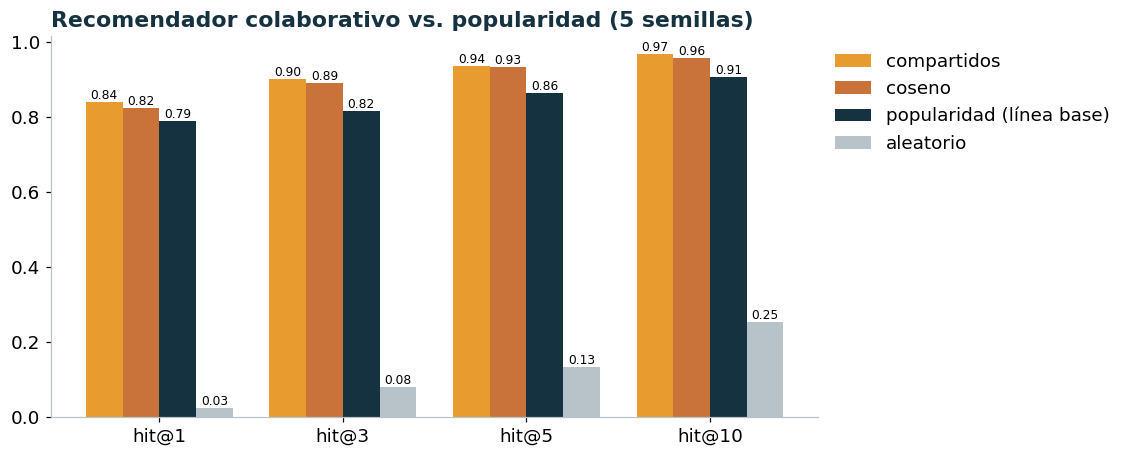


Ejemplo: miembro anónimo #709 pertenece a ['babel', 'facebook', 'reactjs']
  Recomendación (coseno): ['nodejs', 'pytorch', 'reduxjs']
  Recomendación (compartidos): ['nodejs', 'pytorch', 'microsoft']
  Popularidad: ['microsoft', 'Azure', 'apache']

Orden del ataque por intermediación (3 primeras): ['microsoft', 'google', 'Azure'] -> gigante pasa de 33 a 27 organizaciones
           intermediacion  grado  pagerank  miembros  articulación  orgs desconectadas  componentes  caída de la gigante (orgs)  rank_intermediación  rank_impacto  rank_combinado
microsoft           0.401  0.475     0.227      3916          True                   2            3                         3.0                  1.0           2.0             1.5
babel               0.199  0.250     0.038        69          True                   2            2                         3.0                  3.0           2.0             2.5
facebook            0.114  0.200     0.037       107          True                   2  

In [10]:
# ===== Fase 8: recomendador colaborativo sobre el grafo + evaluación hit@k =====
# Conteos sobre el grafo completo: W[a][b] = miembros compartidos; n[o] = miembros de o
W = {o: {} for o in orgs}
for u, v, d in P.edges(data=True): W[u][v] = W[v][u] = d['weight']
n_org = {o: B.degree(o) for o in orgs}

def similitud(wab, na, nb, metodo):
    if metodo == 'coseno':  return wab / np.sqrt(na * nb)
    if metodo == 'jaccard': return wab / (na + nb - wab)
    return wab                                                    # 'compartidos': conteo bruto

def puntajes(propias, metodo, oculta=None):
    # puntaje(o) = suma de similitudes entre o y cada organización propia del miembro.
    # Leave-one-out: si se ocultó la membresía (m, oculta), se descuenta su aporte (-1 compartido, -1 tamaño)
    punt = {}
    for j in propias:
        for o, wjo in W[j].items():
            if o in propias: continue
            wjo_, no_ = (wjo - 1, n_org[o] - 1) if o == oculta else (wjo, n_org[o])
            nj_ = n_org[j]
            if wjo_ > 0: punt[o] = punt.get(o, 0) + similitud(wjo_, nj_, no_, metodo)
    return punt

def pop_de(o, oculta): return n_org[o] - (o == oculta)

def recomendar(m, k=5, metodo='coseno', oculta=None):
    propias = set(B[m]) - {oculta}
    punt = puntajes(propias, metodo, oculta)
    cand = [o for o in orgs if o not in propias]
    return sorted(cand, key=lambda o: (-punt.get(o, 0), -pop_de(o, oculta), o))[:k]   # desempate por popularidad

def popularidad(m, k=5, oculta=None):
    propias = set(B[m]) - {oculta}
    return sorted((o for o in orgs if o not in propias), key=lambda o: (-pop_de(o, oculta), o))[:k]

K = [1, 3, 5, 10]
METODOS = ['coseno', 'jaccard', 'compartidos']
def evaluar(semilla):
    # protocolo leave-one-out: para cada miembro multi-organización se oculta UNA membresía real elegida al azar,
    # se descuenta de los conteos (sin fuga) y se mira si la organización oculta aparece en el top-k
    rng = random.Random(semilla)
    ocultas = {m: rng.choice(sorted(B[m])) for m in multi}
    top = {met: {m: recomendar(m, max(K), met, ocultas[m]) for m in multi} for met in METODOS}
    top['popularidad (línea base)'] = {m: popularidad(m, max(K), ocultas[m]) for m in multi}
    rr = random.Random(semilla + 999)
    top['aleatorio'] = {m: rr.sample([o for o in orgs if o not in set(B[m]) - {ocultas[m]}], max(K)) for m in multi}
    filas = {met: {f'hit@{k}': np.mean([ocultas[m] in t[m][:k] for m in multi]) for k in K} for met, t in top.items()}
    return pd.DataFrame(filas).T, ocultas, top

corridas = [evaluar(s) for s in range(5)]                          # 5 semillas: cambia qué membresía se oculta
evals = [c[0] for c in corridas]
hit = sum(evals) / len(evals); hit_sd = pd.concat(evals).groupby(level=0).std().loc[hit.index]
print(f'Evaluación leave-one-out con {len(multi)} miembros multi-organización (media de 5 semillas):')
print(hit.round(3).to_string()); print('\nDesviación estándar entre semillas:'); print(hit_sd.round(3).to_string())

# Por segmentos (semilla 0): ¿dónde gana el grafo y dónde gana la popularidad?
_, oc0, top0 = corridas[0]
seg = pd.DataFrame({'orgs': [B.degree(m) for m in multi], 'oculta': [oc0[m] for m in multi],
                    **{met: [oc0[m] in top0[met][m][:3] for m in multi] for met in ['coseno', 'compartidos', 'popularidad (línea base)']}})
seg['grupo'] = np.where(seg['orgs'] >= 3, '≥3 orgs', '2 orgs')
seg['oculta gigante'] = np.where(seg['oculta'].isin(['microsoft', 'Azure']), 'oculta = microsoft/Azure', 'oculta = otra org')
cols = ['coseno', 'compartidos', 'popularidad (línea base)']
print('\nhit@3 por segmento (semilla 0):')
print(seg.groupby('grupo')[cols].mean().round(3).assign(n=seg.groupby('grupo').size()).to_string())
print(seg.groupby('oculta gigante')[cols].mean().round(3).assign(n=seg.groupby('oculta gigante').size()).to_string())

# --- Gráfico. Qué analizamos: ¿el recomendador por grafo supera a "recomendar lo más popular"? ---
fig, ax = plt.subplots(figsize=(9, 4.5)); ancho = 0.2
for i, (nombre, c) in enumerate([('compartidos', ACENTO), ('coseno', '#C9733A'), ('popularidad (línea base)', TINTA), ('aleatorio', GRIS)]):
    xs = np.arange(len(K)) + (i - 1.5) * ancho
    ax.bar(xs, hit.loc[nombre], ancho, color=c, label=nombre)
    for x, v in zip(xs, hit.loc[nombre]): ax.text(x, v, f'{v:.2f}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(range(len(K)), [f'hit@{k}' for k in K]); ax.set_title('Recomendador colaborativo vs. popularidad (5 semillas)')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1)); plt.show()

# --- Ejemplo de recomendación (miembro seudonimizado por ética) ---
ej = max(multi, key=lambda m: (B.degree(m), m))
print(f'\nEjemplo: miembro anónimo #{multi.index(ej)} pertenece a {sorted(B[ej])}')
for met in ['coseno', 'compartidos']: print(f'  Recomendación ({met}):', recomendar(ej, 3, met))
print('  Popularidad:', popularidad(ej, 3))

# ===== Desafío 1: las 3 organizaciones puente, combinando evidencia de las fases 3 y 5 =====
desafio = cent.loc[list(G), ['intermediacion', 'grado', 'pagerank', 'miembros']].join(impacto[['articulación', 'orgs desconectadas', 'componentes']])
desafio['caída de la gigante (orgs)'] = [S0 - gigante_rel(P.subgraph(set(P) - {o})) * S0 for o in desafio.index]
desafio['rank_intermediación'] = desafio['intermediacion'].rank(ascending=False)
desafio['rank_impacto'] = desafio['caída de la gigante (orgs)'].rank(ascending=False)
desafio['rank_combinado'] = (desafio['rank_intermediación'] + desafio['rank_impacto']) / 2
orden_ataque = []                                                 # orden del ataque dirigido por intermediación (fase 5)
H = P.copy()
for _ in range(3):
    bc = nx.betweenness_centrality(H, weight='distancia'); v = max(bc, key=lambda k: (bc[k], k)); orden_ataque.append(v); H.remove_node(v)
print('\nOrden del ataque por intermediación (3 primeras):', orden_ataque,
      f'-> gigante pasa de {S0} a {len(max(nx.connected_components(H), key=len))} organizaciones')
print(desafio.sort_values('rank_combinado').head(8).round(3).to_string())
top3_heur = list(desafio.sort_values('rank_combinado').index[:3])
H = P.copy(); H.remove_nodes_from(top3_heur)
print('\nTrío heurístico (rank combinado):', top3_heur, f'-> gigante queda en {len(max(nx.connected_components(H), key=len))} de {S0}')

# Validación: búsqueda exhaustiva del trío que más fragmenta la componente gigante (C(33,3) = 5 456 combinaciones)
from itertools import combinations
def gig_sin(nodos):
    H = G.copy(); H.remove_nodes_from(nodos); return len(max(nx.connected_components(H), key=len))
trios = sorted(((gig_sin(t), t) for t in combinations(sorted(G), 3)))
print('Mejores 5 tríos por fragmentación (gigante restante, trío):', trios[:5])
print('Posición del trío heurístico entre los 5 456:', 1 + [t for _, t in trios].index(tuple(sorted(top3_heur))))
top3_puente = list(trios[0][1])                                   # respuesta del desafío 1: el trío óptimo
H = G.copy(); H.remove_nodes_from(top3_puente)
print(f'\n>>> DESAFÍO 1 - las 3 organizaciones puente: {top3_puente}: al salir, la gigante pasa de {S0} a {gig_sin(top3_puente)} '
      f'organizaciones ({100 * (1 - gig_sin(top3_puente) / S0):.0f}% menos) y la red queda en {nx.number_connected_components(H)} componentes')
print('    quedan fuera de la gigante:', sorted(set(G) - set(max(nx.connected_components(H), key=len)) - set(top3_puente)))
print(desafio.loc[top3_puente, ['intermediacion', 'rank_intermediación', 'grado', 'articulación', 'orgs desconectadas', 'miembros']].round(3).to_string())

**Conclusión de negocio:**
- **Recomendador (leave-one-out, 724 miembros, 5 semillas):** al recomendar por miembros compartidos se obtiene **hit@1 = 0,84, hit@3 = 0,90, hit@5 = 0,94** y hit@10 = 0,97. Con coseno o Jaccard los resultados son casi iguales (0,82 / 0,89–0,90 / 0,93). La **popularidad** se queda en 0,79 / 0,82 / 0,86 / 0,91 y el azar en 0,03 / 0,08 / 0,13 / 0,25. La desviación entre semillas es ≤ 0,012.
- La línea base de popularidad parece fuerte porque el 79 % de los casos son la pareja microsoft–Azure. Cuando la organización oculta **no** es microsoft ni Azure (150 casos), el grafo acierta en el top-3 el **57 %** de las veces y la popularidad solo el **14 %** (unas 4 veces más). Con miembros de 3 organizaciones: 0,74 vs. 0,44.
- Ejemplo: a quien está en babel, facebook y reactjs, el grafo le recomienda nodejs, pytorch y reduxjs. La popularidad le recomendaría microsoft, Azure y apache, que no tienen relación con su perfil.
- **Desafío:**
  1. **Organizaciones puente: microsoft, google y python.** Las tres son puntos de articulación y están en los puestos 1, 4 y 6 por intermediación. Al salir juntas, la componente gigante pasa de 33 a **21 organizaciones (−36 %)** y la red queda en 6 componentes: se desprende todo el ecosistema Google/Python (ansible, deepmind, firebase, flutter, golang, grafana, prometheus), además de ethereum y mongodb. Es el **mejor de los 5 456 tríos posibles** (búsqueda exhaustiva). El trío heurístico microsoft–babel–facebook es el 3.º (deja 24). A nivel de personas, el 57 % de los vínculos depende de un solo desarrollador.
  2. **Recomendador:** supera a la popularidad en todos los k, sobre todo fuera del bloque Microsoft.
  3. **Comunidades:** Leiden (ver fase 7).
  4. **Ética:** son personas reales con nombre. Hay que seudonimizar (como en este notebook), analizar en agregado, usar los datos solo para fortalecer el ecosistema y no para perfilar o "cazar" talento, considerar los homónimos y respetar la LOPDP de Ecuador (2021) y los términos de uso de GitHub.

La **fase de tendencias** usa un modelo de lenguaje. Esta celda lo prepara (Ollama en local, Hugging Face en Colab):

In [11]:
# ===== Modelo de lenguaje (LLM): Ollama en local o un modelo pequeño de Hugging Face en Colab =====
import json, os, urllib.request                       # json: armar/leer mensajes; urllib: peticiones HTTP a la API de Ollama

def _hosts_ollama():   # lista de direcciones donde buscar Ollama
    """Lugares donde puede estar Ollama. Ej.: en Windows es localhost; desde WSL es la IP del Windows anfitrión."""
    hosts = [os.environ.get("OLLAMA_HOST", ""), "http://localhost:11434"]   # OLLAMA_HOST permite forzar otro equipo
    try:                                              # en WSL, el 'nameserver' de resolv.conf es el Windows anfitrión
        ip = [l.split()[1] for l in open("/etc/resolv.conf") if l.startswith("nameserver")][0]   # IP del Windows anfitrión vista desde WSL
        hosts.append(f"http://{ip}:11434")            # ej.: http://172.29.80.1:11434
    except Exception:                                 # en Colab o Windows no hay WSL: se ignora
        pass   # sin host adicional
    return [h if h.startswith("http") else f"http://{h}" for h in hosts if h]   # normaliza: siempre con http://

OLLAMA, MODELO_OLLAMA = None, os.environ.get("MODELO_OLLAMA")  # ej.: MODELO_OLLAMA="llama3.2:3b" para elegir modelo
for h in _hosts_ollama():   # prueba cada dirección
    try:                                              # /api/tags lista los modelos instalados; timeout corto
        modelos = [m["name"] for m in json.load(urllib.request.urlopen(f"{h}/api/tags", timeout=2))["models"]]
        chat = [m for m in modelos if "embed" not in m]   # descartamos modelos de embeddings (no generan texto)
        if chat:   # hay al menos un modelo de chat
            OLLAMA, MODELO_OLLAMA = h, MODELO_OLLAMA or chat[0]   # ej.: ("http://localhost:11434", "qwen3.6:35b-a3b")
            break   # usamos el primero que responde
    except Exception:                                 # no responde: probamos el siguiente host
        continue   # siguiente dirección

try:                                                  # torch solo hace falta sin Ollama (Colab lo trae instalado)
    import torch                                      # para saber si hay GPU (Colab: Entorno > T4 GPU)
    GPU = torch.cuda.is_available()                   # True si hay GPU disponible
except ImportError:                                   # local sin torch: basta con Ollama
    GPU = False                                       # sin torch asumimos CPU
# Con GPU usamos 1.5B (mejor calidad, ~3 GB); sin GPU, 0.5B (~1 GB) para acotar el tiempo de inferencia en CPU
MODELO_HF = "Qwen/Qwen2.5-1.5B-Instruct" if GPU else "Qwen/Qwen2.5-0.5B-Instruct"
# Nota WSL: para usar el Ollama de Windows desde WSL, inicien Ollama en Windows con OLLAMA_HOST=0.0.0.0
_generador = None                                     # se carga solo la primera vez que se necesita
print("LLM:", f"Ollama {MODELO_OLLAMA} en {OLLAMA}" if OLLAMA else f"Hugging Face {MODELO_HF} (se descarga la 1.ª vez)")

def preguntar_llm(prompt, max_tokens=200):   # misma función en local (Ollama) y en Colab (Hugging Face)
    """Envía un prompt y devuelve el texto. Ej.: preguntar_llm("Resume en una frase: ...") -> "El texto trata de ..." """
    global _generador   # reutiliza el modelo ya cargado
    if OLLAMA:                                        # camino 1: servidor Ollama (rápido, privado, sin internet)
        cuerpo = json.dumps({"model": MODELO_OLLAMA, "prompt": prompt, "stream": False, "think": False,
                             "options": {"temperature": 0, "num_predict": max_tokens}}).encode()  # temperature 0 = repetible
        req = urllib.request.Request(f"{OLLAMA}/api/generate", cuerpo, {"Content-Type": "application/json"})   # petición POST a Ollama
        return json.load(urllib.request.urlopen(req, timeout=600))["response"].strip()   # texto de la respuesta
    if _generador is None:                            # camino 2: transformers (Colab ya lo trae instalado)
        from transformers import pipeline   # carga perezosa: solo si no hay Ollama
        _generador = pipeline("text-generation", model=MODELO_HF,
                              device=0 if GPU else -1)   # 0 = primera GPU, -1 = CPU
    salida = _generador([{"role": "user", "content": prompt}], max_new_tokens=max_tokens, do_sample=False)
    return salida[0]["generated_text"][-1]["content"].strip()   # el último mensaje es la respuesta del modelo

LLM: Hugging Face Qwen/Qwen2.5-1.5B-Instruct (se descarga la 1.ª vez)


<a id="fase-9"></a>
## Fase 9: Tendencias: backends de NetworkX y GraphRAG

a) **Backends:** calculen la intermediación de la proyección con NetworkX normal y con `backend="parallel"` (nx-parallel); comparen tiempo y verifiquen que el resultado es el mismo. ¿Desde qué tamaño de red conviene? b) **Mini GraphRAG:** resuman con un LLM las 5 comunidades más grandes de la fase 7 y respondan una pregunta global (¿qué ecosistemas tecnológicos hay en GitHub y qué organizaciones los conectan?). Verifiquen la **fidelidad**: ¿el LLM menciona organizaciones que no están en los datos? Citen la lectura de tendencia de la semana (*Toda base de datos es un grafo*) y, para GraphRAG, Edge et al. (2024).

> **Pregunta de la guía:** Tiempo normal vs. backend parallel y respuesta del mini GraphRAG. ¿El LLM generó organizaciones ausentes en los datos (alucinación)?

**Qué analizamos:** _completar antes del código_

In [12]:
# --- a) Backend de NetworkX: mismo algoritmo, implementación paralela (nx-parallel) ---
import os, time                                         # os.cpu_count(): núcleos; time: cronometrar
backends = nx.utils.backends.backends                   # backends instalados. Ej.: {'parallel': ...}
print("Backends:", list(backends), "| núcleos:", os.cpu_count())
t0 = time.perf_counter()
bc = nx.betweenness_centrality(P, weight="distancia")   # P = su proyección de organizaciones (fase 2)
print(f"normal: {time.perf_counter() - t0:.1f}s")
# completar: nx.config.backends.parallel.n_jobs = -1 y repetir con backend="parallel";
#            comparar tiempo y comprobar que los valores coinciden (diferencia máxima ~0)

# --- b) Mini GraphRAG: comunidades (fase 7) -> resumen por comunidad (LLM) -> respuesta global ---
# comunidades = ...                                     # su mejor partición de la fase 7 (idealmente Leiden)
# for c in sorted(comunidades, key=len, reverse=True)[:5]:
#     lideres = sorted(c, key=lambda n: P.degree(n, weight="weight"), reverse=True)[:8]   # orgs con más miembros compartidos
#     resumen = preguntar_llm(f"Estas organizaciones de GitHub comparten muchos miembros: {lideres}. "
#                             "En 2 frases, ¿qué ecosistema tecnológico forman?")         # ej.: "frameworks de JavaScript"
# completar: pregunta global con los resúmenes + las 5 orgs puente (intermediación) y verificación de fidelidad


Backends: ['parallel', 'cugraph'] | núcleos: 2
normal: 0.0s


**Conclusión de negocio:** _completar después del resultado_

<a id="fase-final"></a>
## Fase final: aplicación al entorno profesional (individual)

¿Qué red de relaciones existe en tu entorno laboral (clientes–productos, empleados–proyectos, proveedores, transacciones…) en Ecuador o tu país? Describe cómo la modelarías como grafo, qué medida de centralidad o de robustez respondería una pregunta de negocio concreta, y qué implicación ética tendría analizar esas relaciones.

Cada integrante responde **por separado** (150–250 palabras). Esta sección se califica de forma individual.

### Integrante 1: Diana Tandalla

En mi trabajo en analítica de datos existe una red natural entre los clientes y los servicios que contratan (tableros, modelos predictivos, automatizaciones), y otra entre consultores y proyectos. La modelaría como en este ejercicio: un grafo bipartito cliente–servicio, o consultor–proyecto. Luego lo proyectaría sobre los servicios, con peso igual al número de clientes que comparten, y usaría distancia = 1/peso para calcular caminos.

Con esto respondería dos preguntas de negocio. La primera es qué servicio ofrecer a cada cliente: un recomendador colaborativo sobre el grafo, evaluado con hit@k frente a recomendar lo más vendido, mostraría si la venta cruzada mejora de verdad. La segunda es de quién depende la operación. La intermediación y los puntos de articulación de la red consultor–proyecto revelarían a las personas que conectan equipos y clientes. La simulación de robustez, con salidas aleatorias frente a dirigidas, cuantificaría el riesgo si una de ellas se va y orientaría la documentación y la rotación del conocimiento. Además, con Leiden agruparía a clientes con necesidades parecidas para diseñar paquetes de servicios.

La implicación ética es que se analizan personas y empresas reales. Aplicaría la Ley Orgánica de Protección de Datos Personales del Ecuador: finalidad limitada, seudonimización y resultados agregados. Una métrica de centralidad no debe usarse para evaluar o sancionar a un colaborador, sino para reducir riesgos y repartir mejor la carga de trabajo.

### Integrante 2: Wilson Paredes

La aplicación práctica de los algoritmos de teoría de grafos, análisis de centralidades, conectividad y recomendación desarrollados en esta práctica aporta un valor estratégico directo al ejercicio profesional del desarrollador de software en el contexto universitario.
En primer lugar, el modelado y análisis de redes bipartitas y sus proyecciones facilitan la comprensión profunda de las relaciones e interacciones complejas dentro del ecosistema universitario. Como desarrollador, esta metodología permite diseñar e implementar módulos analíticos avanzados para los sistemas de gestión académica y de investigación (SIU / LMS), identificando nodos clave como investigadores puente entre diferentes facultades, departamentos o grupos de investigación transdisciplinarios.
En segundo lugar, las métricas de centralidad y las técnicas de detección de comunidades ofrecen un marco sólido para el desarrollo de sistemas de recomendación personalizados orientados a la comunidad universitaria. Esto se traduce en la capacidad de construir funcionalidades inteligentes dentro de las plataformas institucionales, tales como recomendadores de proyectos de vinculación, sugerencia de colaboradores científicos para publicaciones, o la asignación eficiente de mentores y estudiantes en programas de grado y posgrado.
Finalmente, la simulación de resiliencia y la evaluación de robustez en grafos proporcionan criterios metodológicos para mejorar la arquitectura del software y la infraestructura tecnológica de la universidad. El desarrollador puede aplicar estos principios para evaluar la tolerancia a fallos en microservicios, optimizar la topología de redes internas, garantizar la disponibilidad de los sistemas críticos universitarios ante la eventual caída de servidores centrales y estructurar esquemas eficientes de flujo de datos y conocimiento.
De este modo, el dominio de estos conceptos fortalece la capacidad técnica para crear soluciones tecnológicas innovadoras, escalables y con alto impacto en la toma de decisiones basada en datos dentro de la institución de educación superior.


### Integrante 3: Alexander Luna

En el Registro de la Propiedad y Mercantil del Cantón Rumiñahui (RPMR), administro sistemas críticos como FORU (Sistema Registral de Propiedades). En este entorno existe una red compleja entre usuarios/ciudadanos, actos registrales (compraventas, hipotecas, prohibiciones) y predios. Modelaría esta estructura como un grafo bipartito o multipartito, conectando usuarios con predios mediante los trámites y certificaciones solicitadas.
Al proyectar este grafo sobre los tipos de actos registrales o predios, la centralidad de intermediación y la identificación de puntos de articulación responderían a una pregunta fundamental de negocio y gestión pública: ¿cuáles son los trámites nodo crítico o los predios con alta carga registral que podrían generar cuellos de botella e ineficiencias operativas en el flujo institucional? La simulación de resiliencia cuantificaría el impacto de la eventual caída de un módulo registral o la sobrecarga de un trámite en la atención al ciudadano. Aplicando algoritmos de comunidades (Leiden) y sistemas de recomendación (coseno/Jaccard), el sistema podría sugerir de forma proactiva requisitos complementarios o certificar actos vinculados, acelerando el proceso de calificación registral y la consulta de antecedentes nodales.
Desde la perspectiva ética, el tratamiento de datos de propiedad y de identidad ciudadana exige el cumplimiento estricto de la Ley Orgánica de Protección de Datos Personales (LOPDP) de Ecuador. Toda métrica de red o análisis de centralidad debe ejecutarse bajo esquemas de seudonimización y anonimización de titulares, garantizando la finalidad institucional exclusiva (optimización del servicio registral) sin incurrir en perfilamientos patrimoniales o vulneraciones a la privacidad ciudadana.

### Integrante 4: Alejandro Sarmiento

En mi entorno laboral existe una red entre los colaboradores y la base de conocimiento interna: manuales, procedimientos, tickets de soporte y documentación técnica. La modelaría como un grafo bipartito colaborador–documento, donde una arista indica que la persona consultó o editó ese documento. Al proyectarlo sobre los documentos, con peso igual al número de colaboradores que los comparten, obtendría qué conocimientos se usan juntos.
La pregunta de negocio es cómo lograr que cada persona encuentre más rápido la información que necesita. Un recomendador colaborativo, como el de la fase 8, sugeriría documentos relevantes a cada colaborador. Lo evaluaría con hit@k frente a recomendar los más consultados. Además, con Leiden agruparía los documentos en comunidades temáticas y generaría resúmenes por comunidad, al estilo GraphRAG. Así, un asistente de IA podría responder preguntas globales sin inventar información, verificando su fidelidad contra las fuentes reales. La intermediación revelaría qué documentos o expertos conectan áreas distintas y deben mantenerse actualizados.
La implicación ética es que el registro de consultas revela hábitos de trabajo de personas reales. Aplicaría la LOPDP del Ecuador: seudonimización, resultados agregados y finalidad limitada a mejorar el acceso al conocimiento, nunca a vigilar ni evaluar el desempeño individual. También informaría a los colaboradores sobre el uso de la IA.


## Checklist de cierre — Semana 2

- [x] Modelé la red como grafo bipartito y construí la proyección ponderada.
- [x] Calculé e interpreté las 4 centralidades y PageRank tratando el peso como distancia cuando corresponde.
- [x] Simulé robustez ante fallos aleatorios y ataques dirigidos e identifiqué los puntos de articulación.
- [x] Recorrí la red con BFS, DFS, Dijkstra y Floyd-Warshall y sé cuándo no escala.
- [x] Comparé al menos 3 algoritmos de comunidades con modularidad.
- [x] Evalué el recomendador con hit@k contra una línea base.
- [ ] Probé un backend de NetworkX y un mini GraphRAG verificando su fidelidad.
- [x] Completé la reflexión individual (Integrante 1).

**Siguiente paso:** La Semana 3 aplica el mismo análisis a minería de textos y a procesamiento distribuido de grandes volúmenes de datos (Big Data).